# Hydrogen bond comparative analysis

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Load data

Two analysis methods per replicate. 3 WT replicates, 3 S466R replicates.

### WT

In [8]:
wt_dfs = []
for rep in range(1, 4):
    df_gmx = pd.read_csv(f'../../data/1bf5/wt/rep{rep}/analysis/002_hbonds/hbonds_gmx_ext.csv')
    df_mda = pd.read_csv(f'../../data/1bf5/wt/rep{rep}/analysis/002_hbonds/hbonds_mda_ext.csv')
    wt_dfs.append([df_gmx, df_mda])


In [9]:
wt_dfs[0][0].columns

Index(['donor', 'hydrogen', 'acceptor', 'count', 'frame%', 'donor_res_name',
       'donor_res_num', 'donor_atom_name', 'donor_chain', 'acceptor_res_name',
       'acceptor_res_num', 'acceptor_atom_name', 'acceptor_chain',
       'donor_type', 'acceptor_type', 'donor_res_num_adjusted',
       'acceptor_res_num_adjusted', 'donor_section', 'acceptor_section'],
      dtype='object')

### S466R

In [10]:
S466R_dfs = []
for rep in range(1, 4):
    df_gmx = pd.read_csv(f'../../data/1bf5/S466R/rep{rep}/analysis/002_hbonds/hbonds_gmx_ext.csv')
    df_mda = pd.read_csv(f'../../data/1bf5/S466R/rep{rep}/analysis/002_hbonds/hbonds_mda_ext.csv')
    S466R_dfs.append([df_gmx, df_mda])


## Method comparison (gmx vs mda)

Number and ratio of overlapping hydrogen bonds between methods, per replicate.

In [11]:
def method_overlap(df_list, frame_cutoff = 0):
    key_cols = ['donor', 'acceptor']
    for i in range(len(df_list)):

        gmx_filtered = df_list[i][0][key_cols][df_list[i][0]['frame%'] > frame_cutoff]
        mda_filtered = df_list[i][1][key_cols][df_list[i][1]['frame%'] > frame_cutoff]

        overlap1 = pd.merge(
            gmx_filtered,
            mda_filtered,
            how='inner'
        )

        total_bonds = gmx_filtered.shape[0] + mda_filtered.shape[0]
        ratio = len(overlap1) / total_bonds

        print(f"Replicate {i}")
        print(f"Number of overlapping hydrogen bonds: {len(overlap1)} out of {total_bonds}. Ratio: {ratio}")

In [12]:
method_overlap(wt_dfs)

Replicate 0
Number of overlapping hydrogen bonds: 294 out of 403. Ratio: 0.7295285359801489
Replicate 1
Number of overlapping hydrogen bonds: 396 out of 470. Ratio: 0.8425531914893617
Replicate 2
Number of overlapping hydrogen bonds: 391 out of 457. Ratio: 0.8555798687089715


In [13]:
method_overlap(S466R_dfs)

Replicate 0
Number of overlapping hydrogen bonds: 432 out of 486. Ratio: 0.8888888888888888
Replicate 1
Number of overlapping hydrogen bonds: 330 out of 404. Ratio: 0.8168316831683168
Replicate 2
Number of overlapping hydrogen bonds: 527 out of 578. Ratio: 0.9117647058823529


Same overlap analysis, filtering out hydrogen bonds identified in < 10 \% of the frames.

In [14]:
method_overlap(wt_dfs, 10)

Replicate 0
Number of overlapping hydrogen bonds: 50 out of 88. Ratio: 0.5681818181818182
Replicate 1
Number of overlapping hydrogen bonds: 38 out of 60. Ratio: 0.6333333333333333
Replicate 2
Number of overlapping hydrogen bonds: 42 out of 68. Ratio: 0.6176470588235294


In [15]:
method_overlap(S466R_dfs, 10)

Replicate 0
Number of overlapping hydrogen bonds: 43 out of 69. Ratio: 0.6231884057971014
Replicate 1
Number of overlapping hydrogen bonds: 59 out of 94. Ratio: 0.6276595744680851
Replicate 2
Number of overlapping hydrogen bonds: 17 out of 39. Ratio: 0.4358974358974359


Plot overlap number.

In [16]:
wt_dfs_flat =  [x for xs in wt_dfs for x in xs]
S466R_dfs_flat =  [x for xs in S466R_dfs for x in xs]
df_all = pd.concat(wt_dfs_flat + S466R_dfs_flat)

In [17]:
len(wt_dfs_flat)

6

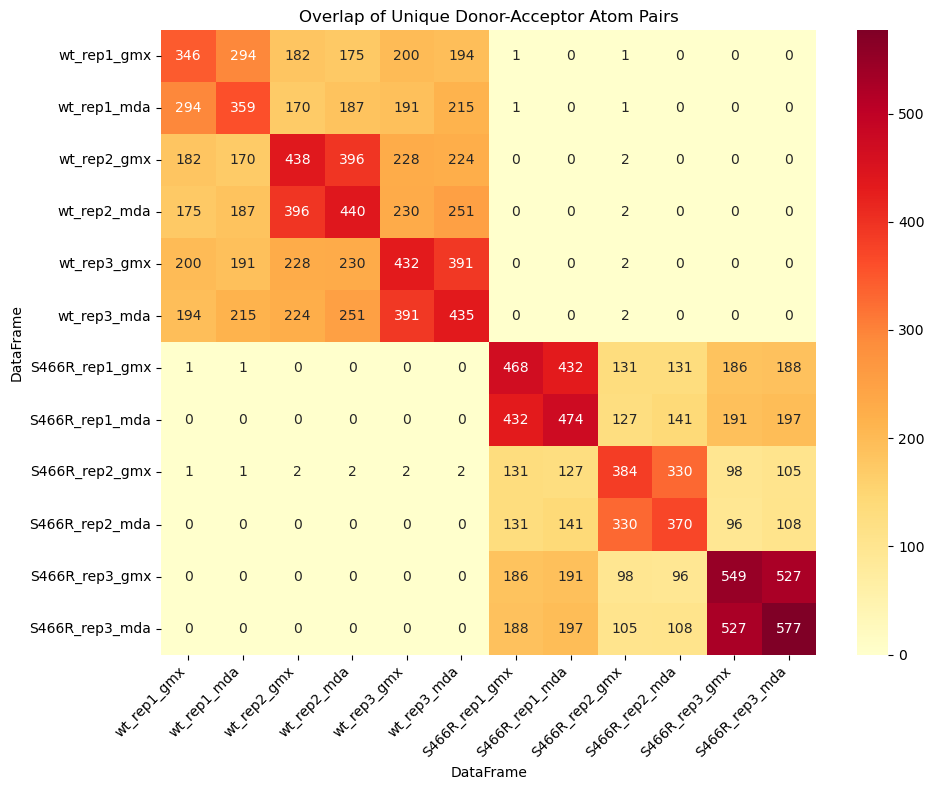

In [18]:
# Combine WT and S466R DataFrames
all_dfs_flat = wt_dfs_flat + S466R_dfs_flat

# Key columns for triplets
key_cols = ['donor', 'acceptor']

# Labels for DataFrames
labels = ['wt_rep1_gmx', 'wt_rep1_mda', 
          'wt_rep2_gmx', 'wt_rep2_mda', 'wt_rep3_gmx', 'wt_rep3_mda',
          'S466R_rep1_gmx', 'S466R_rep1_mda', 
          'S466R_rep2_gmx', 'S466R_rep2_mda', 'S466R_rep3_gmx', 'S466R_rep3_mda']

# Verify lengths match
n_labels = len(labels)
n_dfs = len(all_dfs_flat)
if n_labels != n_dfs:
    raise ValueError(f"Number of labels ({n_labels}) does not match number of DataFrames ({n_dfs})")

# Matrix to store overlap counts
overlap_matrix = np.zeros((n_labels, n_labels))

# Calculate overlaps between each pair of DataFrames
for i in range(n_labels):
    for j in range(n_labels):
        # Get unique triplets from each DataFrame
        df1_triplets = all_dfs_flat[i][key_cols]
        df2_triplets = all_dfs_flat[j][key_cols]
        
        # Find overlapping triplets
        overlap = pd.merge(df1_triplets, df2_triplets, how='inner')
        
        # Store the count of overlapping triplets
        overlap_matrix[i, j] = len(overlap)

# Create heatmap
plt.figure(figsize=(10, 8))  # Adjusted size for more labels
sns.heatmap(overlap_matrix, 
            annot=True, 
            fmt='.0f',  
            cmap='YlOrRd', 
            xticklabels=labels,
            yticklabels=labels)

# Customize the plot
plt.title('Overlap of Unique Donor-Acceptor Atom Pairs')
plt.xlabel('DataFrame')
plt.ylabel('DataFrame')

# Rotate x-axis labels for better readability
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)

# Adjust layout to prevent label cutoff
plt.tight_layout()

# Show the plot
plt.show()

Verify that there are no common donor-acceptor atom pairs identified between WT and S466R.

In [19]:
# Key columns
key_cols = ['donor', 'acceptor']

# Aggregate unique triplets from wt_dfs_flat
wt_triplets = pd.concat([df[key_cols] for df in wt_dfs_flat], ignore_index=True).drop_duplicates()

# Aggregate unique triplets from S466R_dfs_flat
S466R_triplets = pd.concat([df[key_cols] for df in S466R_dfs_flat], ignore_index=True).drop_duplicates()

# Find overlapping triplets
overlap = pd.merge(wt_triplets, S466R_triplets, how='inner', on=key_cols)

# Report results
if overlap.empty:
    print("No common ['donor', 'hydrogen', 'acceptor'] triplets between WT and S466R DataFrames.")
else:
    print(f"Found {len(overlap)} common triplets:")
    print(overlap)

# Optional: Show number of unique triplets in each group
print(f"Unique WT triplets: {len(wt_triplets)}")
print(f"Unique S466R triplets: {len(S466R_triplets)}")

Found 2 common triplets:
   donor  acceptor
0   3216     19897
1   4738     20190
Unique WT triplets: 339
Unique S466R triplets: 422


For a less stringent comparison, consider the donor and acceptor residue numbers instead of specific atoms.

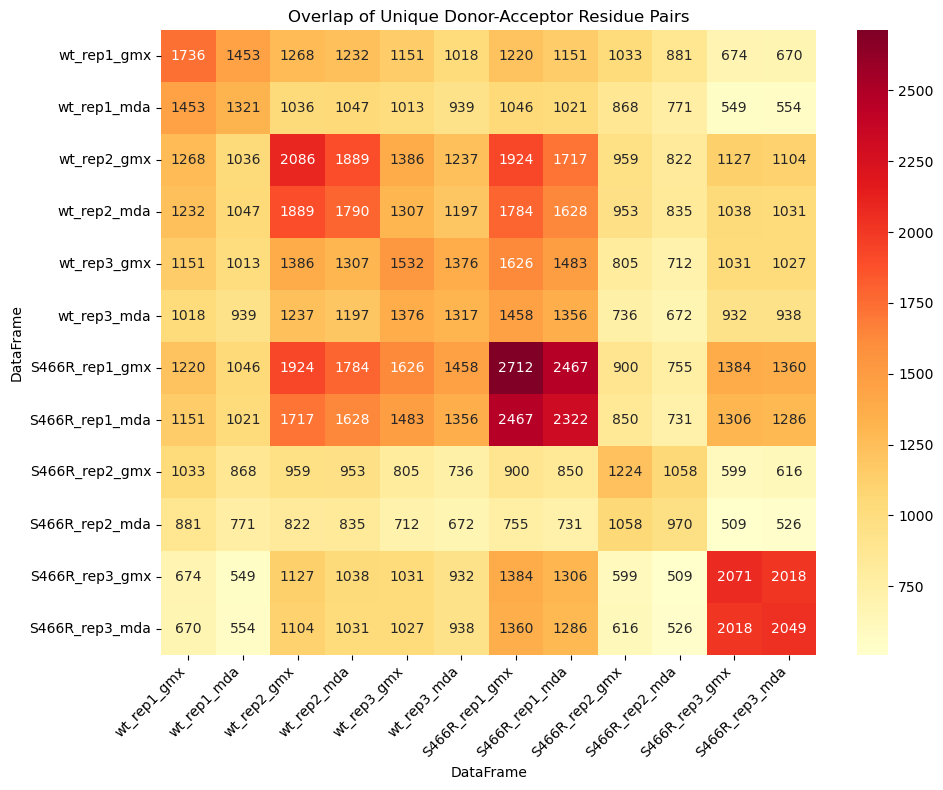

In [20]:
# Combine WT and S466R DataFrames
all_dfs_flat = wt_dfs_flat + S466R_dfs_flat

# Key columns for triplets
key_cols = ['donor_res_num', 'acceptor_res_num']

# Labels for DataFrames
labels = ['wt_rep1_gmx', 'wt_rep1_mda', 
          'wt_rep2_gmx', 'wt_rep2_mda', 'wt_rep3_gmx', 'wt_rep3_mda',
          'S466R_rep1_gmx', 'S466R_rep1_mda', 
          'S466R_rep2_gmx', 'S466R_rep2_mda', 'S466R_rep3_gmx', 'S466R_rep3_mda']

# Verify lengths match
n_labels = len(labels)
n_dfs = len(all_dfs_flat)
if n_labels != n_dfs:
    raise ValueError(f"Number of labels ({n_labels}) does not match number of DataFrames ({n_dfs})")

# Matrix to store overlap counts
overlap_matrix = np.zeros((n_labels, n_labels))

# Calculate overlaps between each pair of DataFrames
for i in range(n_labels):
    for j in range(n_labels):
        # Get unique triplets from each DataFrame
        df2_triplets = all_dfs_flat[j][key_cols]
        df1_triplets = all_dfs_flat[i][key_cols]
        
        # Find overlapping triplets
        overlap = pd.merge(df1_triplets, df2_triplets, how='inner')
        
        # Store the count of overlapping triplets
        overlap_matrix[i, j] = len(overlap)

# Create heatmap
plt.figure(figsize=(10, 8))  # Adjusted size for more labels
sns.heatmap(overlap_matrix, 
            annot=True, 
            fmt='.0f',  
            cmap='YlOrRd', 
            xticklabels=labels,
            yticklabels=labels)

# Customize the plot
plt.title('Overlap of Unique Donor-Acceptor Residue Pairs')
plt.xlabel('DataFrame')
plt.ylabel('DataFrame')

# Rotate x-axis labels for better readability
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)

# Adjust layout to prevent label cutoff
plt.tight_layout()

# Show the plot
plt.show()

Plot overlap ratios.

[50, 54, 53, 57, 60, 64, 46, 51, 58, 57, 76, 74]


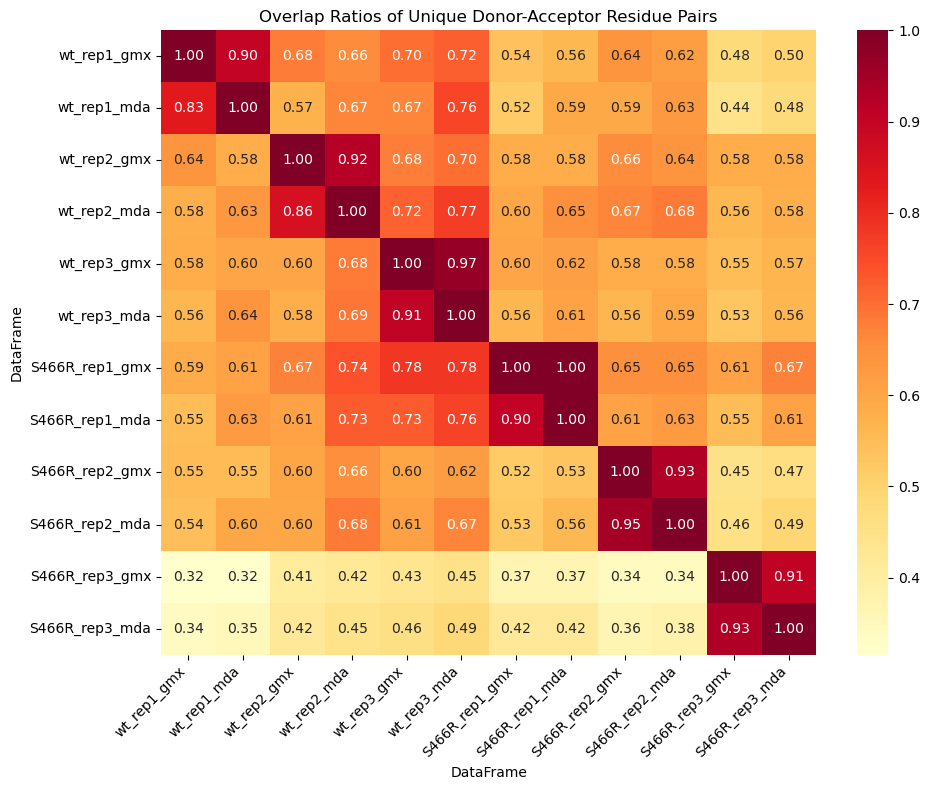

In [21]:
key_cols = ['donor_res_num', 'acceptor_res_num']
total_unique = [len(df[key_cols].drop_duplicates()) for df in all_dfs_flat]

print(total_unique)


# Matrix to store overlap counts
overlap_ratio_matrix = np.zeros((n_labels, n_labels))

# Calculate overlaps between each pair of DataFrames
for i in range(n_labels):
    for j in range(n_labels):
        # Get unique triplets from each DataFrame
        df1_triplets = all_dfs_flat[i][key_cols].drop_duplicates()
        df2_triplets = all_dfs_flat[j][key_cols].drop_duplicates()
        
        # Find overlapping triplets
        overlap = pd.merge(df1_triplets, df2_triplets, how='inner')
        
        
        # Calculate ratio relative to total unique triplets in df[i] (y-axis)
        ratio = len(overlap) / total_unique[i] if total_unique[i] > 0 else 0
        overlap_ratio_matrix[i, j] = ratio

# Create heatmap
plt.figure(figsize=(10, 8))  # Adjusted size for more labels
sns.heatmap(overlap_ratio_matrix, 
            annot=True, 
            fmt='.2f',  
            cmap='YlOrRd', 
            xticklabels=labels,
            yticklabels=labels)

# Customize the plot
plt.title('Overlap Ratios of Unique Donor-Acceptor Residue Pairs')
plt.xlabel('DataFrame')
plt.ylabel('DataFrame')

# Rotate x-axis labels for better readability
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)

# Adjust layout to prevent label cutoff
plt.tight_layout()

# Show the plot
plt.show()

[149, 134, 159, 154, 155, 147, 157, 156, 145, 127, 188, 182]


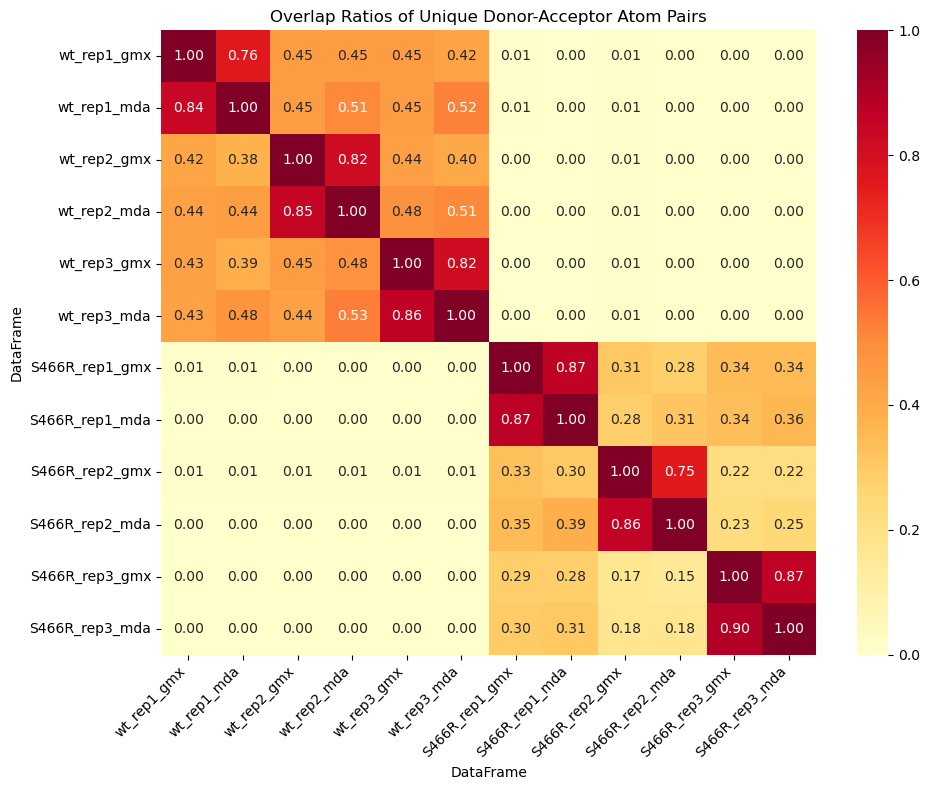

In [22]:
key_cols = ['donor', 'acceptor']
total_unique = [len(df[key_cols].drop_duplicates()) for df in all_dfs_flat]

print(total_unique)


# Matrix to store overlap counts
overlap_ratio_matrix = np.zeros((n_labels, n_labels))

# Calculate overlaps between each pair of DataFrames
for i in range(n_labels):
    for j in range(n_labels):
        # Get unique triplets from each DataFrame
        df1_triplets = all_dfs_flat[i][key_cols].drop_duplicates()
        df2_triplets = all_dfs_flat[j][key_cols].drop_duplicates()
        
        # Find overlapping triplets
        overlap = pd.merge(df1_triplets, df2_triplets, how='inner')
        
        
        # Calculate ratio relative to total unique triplets in df[i] (y-axis)
        ratio = len(overlap) / total_unique[i] if total_unique[i] > 0 else 0
        overlap_ratio_matrix[i, j] = ratio

# Create heatmap
plt.figure(figsize=(10, 8))  # Adjusted size for more labels
sns.heatmap(overlap_ratio_matrix, 
            annot=True, 
            fmt='.2f',  
            cmap='YlOrRd', 
            xticklabels=labels,
            yticklabels=labels)

# Customize the plot
plt.title('Overlap Ratios of Unique Donor-Acceptor Atom Pairs')
plt.xlabel('DataFrame')
plt.ylabel('DataFrame')

# Rotate x-axis labels for better readability
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)

# Adjust layout to prevent label cutoff
plt.tight_layout()

# Show the plot
plt.show()

## Bond distribution

In [23]:
combined_df_wt = pd.concat(wt_dfs_flat)

In [24]:
combined_df_wt.columns

Index(['donor', 'hydrogen', 'acceptor', 'count', 'frame%', 'donor_res_name',
       'donor_res_num', 'donor_atom_name', 'donor_chain', 'acceptor_res_name',
       'acceptor_res_num', 'acceptor_atom_name', 'acceptor_chain',
       'donor_type', 'acceptor_type', 'donor_res_num_adjusted',
       'acceptor_res_num_adjusted', 'donor_section', 'acceptor_section'],
      dtype='object')

In [25]:
combined_df_wt["donor_type"].value_counts()

donor_type
protein    1290
DNA          40
Name: count, dtype: int64

In [26]:
print(combined_df_wt[combined_df_wt["donor_type"] == "protein"]["frame%"].mean())
print(combined_df_wt[combined_df_wt["donor_type"] == "DNA"]["frame%"].mean())

7.381533195486684
0.9965034965034965


As expected, the protein (amino acids) acts as donor in the majority of identified hydrogen bonds and the average number of frames in which these bonds are identified is higher, indicating the positions that lead to them are more stable in time. Therefore, the analysis focuses on the protein as donor and DNA as acceptor in hydrogen bonds.

### WT

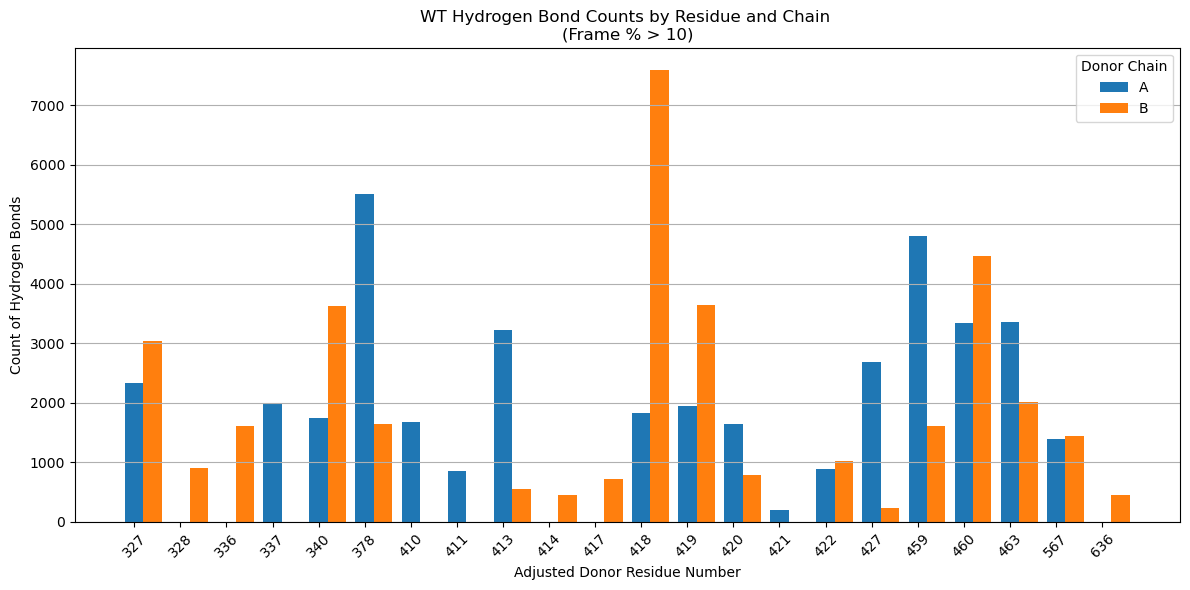

In [27]:
filtered_df = combined_df_wt[combined_df_wt['frame%'] > 10]

# Pivot the data with aggregation (sum) for duplicate entries
pivot_df = pd.pivot_table(filtered_df, 
                         index='donor_res_num_adjusted',
                         columns='donor_chain',
                         values='count',
                         aggfunc='sum',  # Sum counts for duplicate entries
                         fill_value=0)   # Replace NaN with 0

# Create the plot
plt.figure(figsize=(12, 6))

# Get unique acceptor_section values
sections = pivot_df.columns
n_sections = len(sections)

# Set bar width and positions
bar_width = 0.8 / n_sections  # Adjust width based on number of groups
x = np.arange(len(pivot_df.index))  # Positions for each donor residue

# Plot bars for each acceptor_section
for i, section in enumerate(sections):
    plt.bar(x + i * bar_width, 
            pivot_df[section], 
            width=bar_width, 
            label=section,
            align='edge')

# Customize the plot
plt.xlabel('Adjusted Donor Residue Number')
plt.ylabel('Count of Hydrogen Bonds')
plt.title('WT Hydrogen Bond Counts by Residue and Chain \n(Frame % > 10)')
plt.xticks(x + bar_width * (n_sections - 1) / 2, pivot_df.index, rotation=45)
plt.grid(axis = 'y')
plt.legend(title='Donor Chain')
plt.tight_layout()

# Show the plot
plt.show()

Acceptor section. Are the acceptor atoms in the DNA backbone or in the bases?

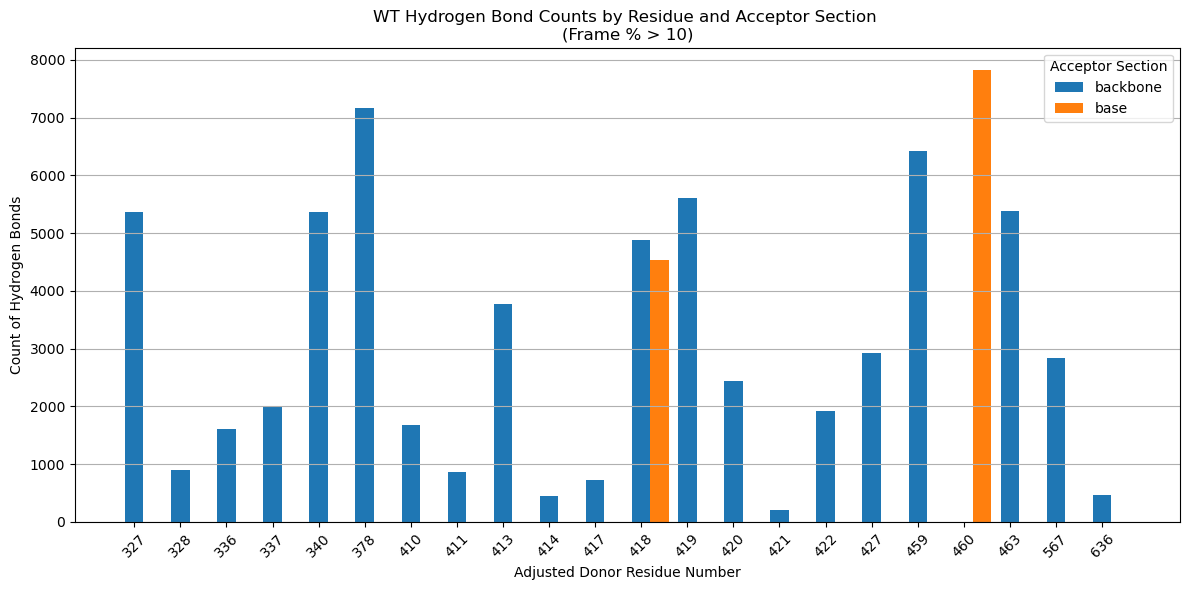

In [28]:
filtered_df = combined_df_wt[combined_df_wt['frame%'] > 10]

# Pivot the data with aggregation (sum) for duplicate entries
pivot_df = pd.pivot_table(filtered_df, 
                         index='donor_res_num_adjusted',
                         columns='acceptor_section',
                         values='count',
                         aggfunc='sum',  # Sum counts for duplicate entries
                         fill_value=0)   # Replace NaN with 0

# Create the plot
plt.figure(figsize=(12, 6))

# Get unique acceptor_section values
sections = pivot_df.columns
n_sections = len(sections)

# Set bar width and positions
bar_width = 0.8 / n_sections  # Adjust width based on number of groups
x = np.arange(len(pivot_df.index))  # Positions for each donor residue

# Plot bars for each acceptor_section
for i, section in enumerate(sections):
    plt.bar(x + i * bar_width, 
            pivot_df[section], 
            width=bar_width, 
            label=section,
            align='edge')

# Customize the plot
plt.xlabel('Adjusted Donor Residue Number')
plt.ylabel('Count of Hydrogen Bonds')
plt.title('WT Hydrogen Bond Counts by Residue and Acceptor Section \n(Frame % > 10)')
plt.xticks(x + bar_width * (n_sections - 1) / 2, pivot_df.index, rotation=45)
plt.grid(axis = 'y')
plt.legend(title='Acceptor Section')
plt.tight_layout()

# Show the plot
plt.show()

#### Summary tables
For 3 replicates and 2 methods, a threshold of count > 600 is equivalent to > 10%.

In [29]:
occ_th = 100 * len(wt_dfs) * len(wt_dfs[0])
occ_th

600

In [30]:
total_frames_wt = 1000 * len(wt_dfs) * len(wt_dfs[0])
total_frames_wt

6000

**Monomer A**

In [31]:
group_columns = combined_df_wt.columns.difference(["frame%", "count", "hydrogen"])
wt_count = combined_df_wt.groupby(list(group_columns))['count'].sum().reset_index()

wt_count.sort_values("count", ascending=False).head()

,acceptor,acceptor_atom_name,acceptor_chain,acceptor_res_name,acceptor_res_num,acceptor_res_num_adjusted,acceptor_section,acceptor_type,donor,donor_atom_name,donor_chain,donor_res_name,donor_res_num,donor_res_num_adjusted,donor_section,donor_type,count
40,19049,OP2,C,DT,8,8,backbone,DNA,5365,OG,A,SER,324,459,DBD,protein,4800
37,19048,OP1,C,DT,8,8,backbone,DNA,4104,NH1,A,ARG,243,378,DBD,protein,4438
226,19827,O4,D,DT,9,9,base,DNA,14791,ND2,B,ASN,325,460,DBD,protein,2800
69,19172,OP1,C,DC,12,12,backbone,DNA,12629,OG1,B,THR,192,327,DBD,protein,2710
30,19016,OP1,C,DT,7,7,backbone,DNA,4874,OG1,A,THR,292,427,DBD,protein,2690


In [32]:
wt_count[(wt_count['donor_chain'] == 'A') & (wt_count["count"] > occ_th)].shape

(20, 17)

In [33]:
summary_cols = wt_count.columns.difference(["acceptor", "donor", "hydrogen", "acceptor_type", "donor_type", "donor_chain", "donor_res_num", "acceptor_res_num"])
wt_count[(wt_count['donor_chain'] == 'A') & (wt_count["count"] > occ_th)].sort_values('count', ascending=False)[summary_cols]

,acceptor_atom_name,acceptor_chain,acceptor_res_name,acceptor_res_num_adjusted,acceptor_section,count,donor_atom_name,donor_res_name,donor_res_num_adjusted,donor_section
40,OP2,C,DT,8,backbone,4800,OG,SER,459,DBD
37,OP1,C,DT,8,backbone,4438,NH1,ARG,378,DBD
30,OP1,C,DT,7,backbone,2690,OG1,THR,427,DBD
47,OP1,C,DT,9,backbone,2560,NZ,LYS,413,DBD
41,OP2,C,DT,8,backbone,2375,NE2,GLN,463,DBD
48,OP2,C,DT,9,backbone,1999,OG1,THR,337,DBD
245,OP2,D,DG,12,backbone,1930,OG1,THR,327,DBD
52,O4,C,DT,9,base,1810,ND2,ASN,460,DBD
252,OP1,D,DG,13,backbone,1788,NZ,LYS,567,LD
45,OP1,C,DT,9,backbone,1712,NZ,LYS,410,DBD


In [34]:
wt_monoA_summary = wt_count[(wt_count['donor_chain'] == 'A') & (wt_count["count"] > occ_th)][summary_cols]
wt_monoA_summary['occupancy'] = round(wt_monoA_summary['count'] / total_frames_wt, 2)
wt_monoA_summary.sort_values("occupancy", ascending=False).head()

,acceptor_atom_name,acceptor_chain,acceptor_res_name,acceptor_res_num_adjusted,acceptor_section,count,donor_atom_name,donor_res_name,donor_res_num_adjusted,donor_section,occupancy
40,OP2,C,DT,8,backbone,4800,OG,SER,459,DBD,0.80
37,OP1,C,DT,8,backbone,4438,NH1,ARG,378,DBD,0.74
30,OP1,C,DT,7,backbone,2690,OG1,THR,427,DBD,0.45
47,OP1,C,DT,9,backbone,2560,NZ,LYS,413,DBD,0.43
41,OP2,C,DT,8,backbone,2375,NE2,GLN,463,DBD,0.40


**Monomer B**

In [35]:
wt_count[(wt_count['donor_chain'] == 'B') & (wt_count["count"] > occ_th)].shape

(26, 17)

In [36]:
summary_cols = wt_count.columns.difference(["acceptor", "donor", "hydrogen", "acceptor_type", "donor_type", "donor_chain", "donor_res_num", "acceptor_res_num"])
wt_count[(wt_count['donor_chain'] == 'B') & (wt_count["count"] > occ_th)].sort_values('count', ascending=False)[summary_cols]

,acceptor_atom_name,acceptor_chain,acceptor_res_name,acceptor_res_num_adjusted,acceptor_section,count,donor_atom_name,donor_res_name,donor_res_num_adjusted,donor_section
226,O4,D,DT,9,base,2800,ND2,ASN,460,DBD
69,OP1,C,DC,12,backbone,2710,OG1,THR,327,DBD
77,OP1,C,DG,13,backbone,2140,NZ,LYS,567,LD
74,OP2,C,DC,12,backbone,1893,NZ,LYS,336,DBD
212,OP2,D,DT,8,backbone,1817,NE2,GLN,463,DBD
211,OP2,D,DT,8,backbone,1633,OG,SER,459,DBD
138,OP1,C,DA,21,backbone,1576,OG1,THR,419,DBD
104,O2,C,DT,18,base,1439,NH1,ARG,418,DBD
162,N3,D,DA,6,base,1381,NH1,ARG,418,DBD
105,O2,C,DT,18,base,1332,NH2,ARG,418,DBD


In [37]:
wt_monoB_summary = wt_count[(wt_count['donor_chain'] == 'B') & (wt_count["count"] > occ_th)][summary_cols]
wt_monoB_summary['occupancy'] = round(wt_monoB_summary['count'] / total_frames_wt, 2)
wt_monoB_summary.sort_values("occupancy", ascending=False).head()

,acceptor_atom_name,acceptor_chain,acceptor_res_name,acceptor_res_num_adjusted,acceptor_section,count,donor_atom_name,donor_res_name,donor_res_num_adjusted,donor_section,occupancy
226,O4,D,DT,9,base,2800,ND2,ASN,460,DBD,0.47
69,OP1,C,DC,12,backbone,2710,OG1,THR,327,DBD,0.45
77,OP1,C,DG,13,backbone,2140,NZ,LYS,567,LD,0.36
74,OP2,C,DC,12,backbone,1893,NZ,LYS,336,DBD,0.32
212,OP2,D,DT,8,backbone,1817,NE2,GLN,463,DBD,0.30


In [38]:
wt_summary = pd.concat([wt_monoA_summary, wt_monoB_summary],keys= ['Monomer A', 'Monomer B'])

In [39]:
wt_summary

acceptor_atom_name acceptor_chain acceptor_res_name  \
Monomer A 28                 O4'              C                DG   
          30                 OP1              C                DT   
          32                 OP2              C                DT   
          37                 OP1              C                DT   
          38                 OP2              C                DT   
          40                 OP2              C                DT   
          41                 OP2              C                DT   
          44                 O3'              C                DT   
          45                 OP1              C                DT   
          47                 OP1              C                DT   
          48                 OP2              C                DT   
          50                 OP2              C                DT   
          52                  O4              C                DT   
          236                OP1              D                DC   
          245                OP2              D                DG   
          252                OP1              D                DG   
          254                OP2              D                DG   
          266                 O6              D                DG   
          296                OP1              D                DG   
          320                O3'              D                DG   
Monomer B 62                 OP1              C                DC   
          63                 OP1              C                DC   
          64                 OP2              C                DC   
          69                 OP1              C                DC   
          74                 OP2              C                DC   
          77                 OP1              C                DG   
          87                 OP1              C                DG   
          90                 OP2              C                DG   
          93                  N7              C                DG   
          94                  O6              C                DG   
          104                 O2              C                DT   
          105                 O2              C                DT   
          138                OP1              C                DA   
          162                 N3              D                DA   
          167                OP1              D                DT   
          168                OP1              D                DT   
          169                OP1              D                DT   
          170                OP1              D                DT   
          172                OP1              D                DT   
          200                OP1              D                DT   
          201                OP1              D                DT   
          211                OP2              D                DT   
          212                OP2              D                DT   
          219                 O4              D                DT   
          222                OP1              D                DT   
          226                 O4              D                DT   

               acceptor_res_num_adjusted acceptor_section  count  \
Monomer A 28                           6         backbone    630   
          30                           7         backbone   2690   
          32                           7         backbone   1238   
          37                           8         backbone   4438   
          38                           8         backbone   1114   
          40                           8         backbone   4800   
          41                           8         backbone   2375   
          44                           8         backbone   1303   
          45                           9         backbone   1712   
          47                           9         backbone   2560   
          48          

In [40]:
wt_summary.to_csv('wt_summary.csv')

### S466R

Find unique pairs of donor-acceptor atoms and sum their counts across replicates and methods. The hydrogen atom number is not taken into account to consider it as the "same bond".

In [41]:
combined_df_S466R = pd.concat(S466R_dfs_flat)

In [42]:
group_columns = combined_df_S466R.columns.difference(["frame%", "count", "hydrogen"])
S466R_count = combined_df_S466R.groupby(list(group_columns))['count'].sum().reset_index()

S466R_count.sort_values("count", ascending=False).head()

,acceptor,acceptor_atom_name,acceptor_chain,acceptor_res_name,acceptor_res_num,acceptor_res_num_adjusted,acceptor_section,acceptor_type,donor,donor_atom_name,donor_chain,donor_res_name,donor_res_num,donor_res_num_adjusted,donor_section,donor_type,count
77,19075,OP2,C,DT,8,8,backbone,DNA,5365,OG,A,SER,324,459,DBD,protein,4686
278,19770,OP2,D,DT,7,7,backbone,DNA,14848,NE2,B,GLN,328,463,DBD,protein,3588
314,19853,O4,D,DT,9,9,base,DNA,14804,ND2,B,ASN,325,460,DBD,protein,3057
111,19198,OP1,C,DC,12,12,backbone,DNA,12642,OG1,B,THR,192,327,DBD,protein,2542
80,19075,OP2,C,DT,8,8,backbone,DNA,5422,NE2,A,GLN,328,463,DBD,protein,2024


In [43]:
S466R_count.shape

(422, 17)

Comparison between monomers A and B.

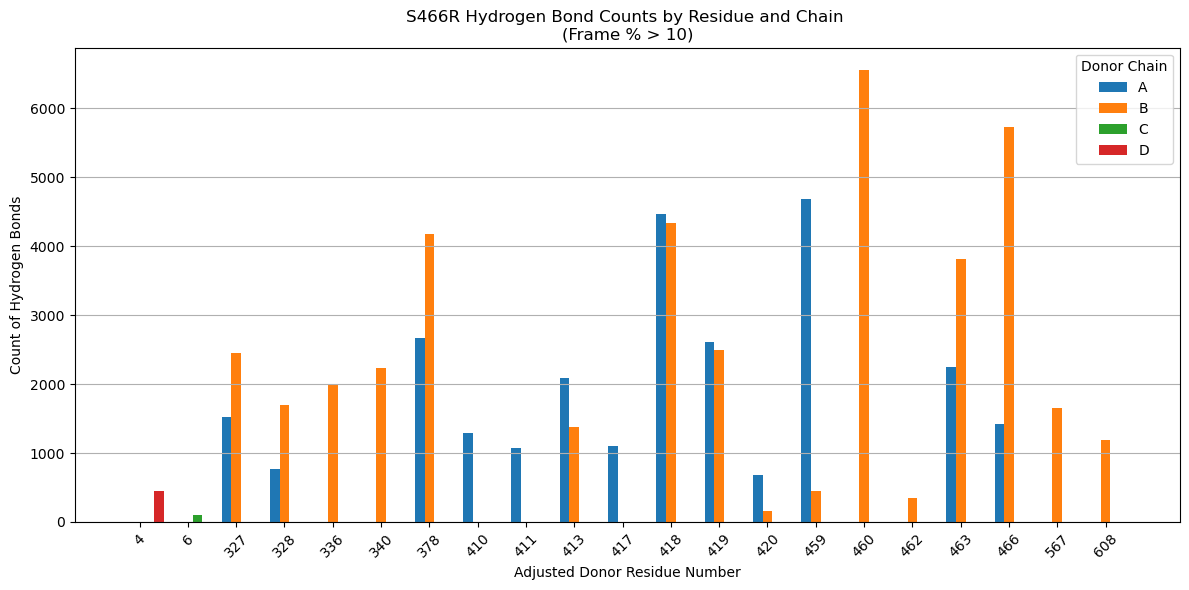

In [44]:
filtered_df = combined_df_S466R[combined_df_S466R['frame%'] > 10]

# Pivot the data with aggregation (sum) for duplicate entries
pivot_df = pd.pivot_table(filtered_df, 
                         index='donor_res_num_adjusted',
                         columns='donor_chain',
                         values='count',
                         aggfunc='sum',  # Sum counts for duplicate entries
                         fill_value=0)   # Replace NaN with 0

# Create the plot
plt.figure(figsize=(12, 6))

# Get unique acceptor_section values
sections = pivot_df.columns
n_sections = len(sections)

# Set bar width and positions
bar_width = 0.8 / n_sections  # Adjust width based on number of groups
x = np.arange(len(pivot_df.index))  # Positions for each donor residue

# Plot bars for each acceptor_section
for i, section in enumerate(sections):
    plt.bar(x + i * bar_width, 
            pivot_df[section], 
            width=bar_width, 
            label=section,
            align='edge')

# Customize the plot
plt.xlabel('Adjusted Donor Residue Number')
plt.ylabel('Count of Hydrogen Bonds')
plt.title('S466R Hydrogen Bond Counts by Residue and Chain \n(Frame % > 10)')
plt.xticks(x + bar_width * (n_sections - 1) / 2, pivot_df.index, rotation=45)
plt.grid(axis = 'y')
plt.legend(title='Donor Chain')
plt.tight_layout()

# Show the plot
plt.show()

Acceptor section. Are the acceptor atoms in the DNA backbone or in the bases?

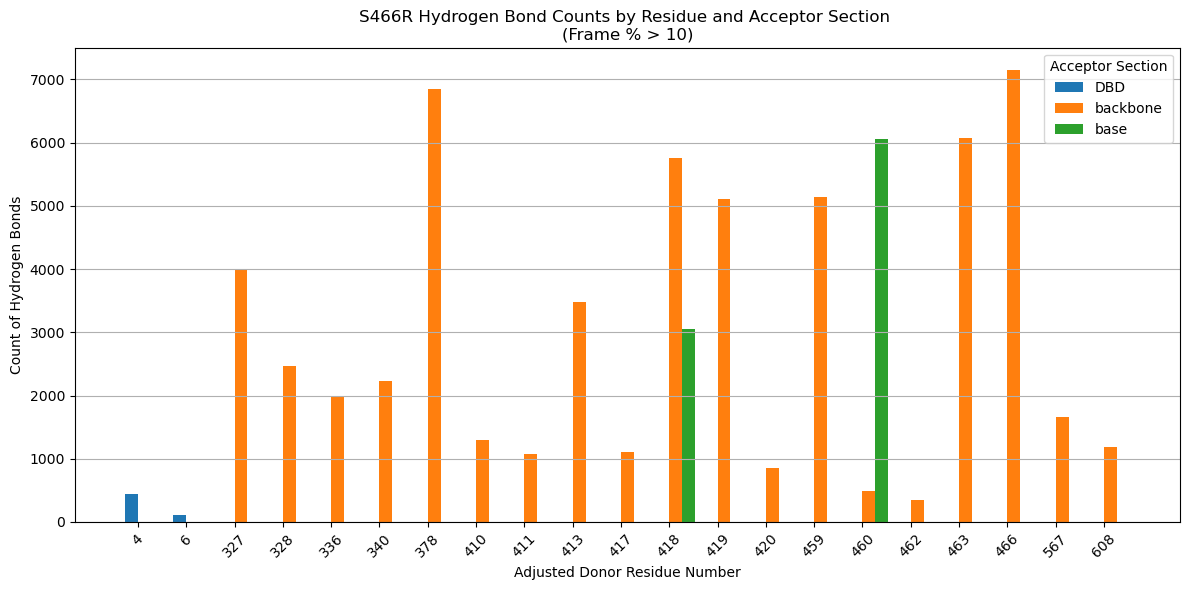

In [45]:
filtered_df = combined_df_S466R[combined_df_S466R['frame%'] > 10]

# Pivot the data with aggregation (sum) for duplicate entries
pivot_df = pd.pivot_table(filtered_df, 
                         index='donor_res_num_adjusted',
                         columns='acceptor_section',
                         values='count',
                         aggfunc='sum',  # Sum counts for duplicate entries
                         fill_value=0)   # Replace NaN with 0

# Create the plot
plt.figure(figsize=(12, 6))

# Get unique acceptor_section values
sections = pivot_df.columns
n_sections = len(sections)

# Set bar width and positions
bar_width = 0.8 / n_sections  # Adjust width based on number of groups
x = np.arange(len(pivot_df.index))  # Positions for each donor residue

# Plot bars for each acceptor_section
for i, section in enumerate(sections):
    plt.bar(x + i * bar_width, 
            pivot_df[section], 
            width=bar_width, 
            label=section,
            align='edge')

# Customize the plot
plt.xlabel('Adjusted Donor Residue Number')
plt.ylabel('Count of Hydrogen Bonds')
plt.title('S466R Hydrogen Bond Counts by Residue and Acceptor Section \n(Frame % > 10)')
plt.xticks(x + bar_width * (n_sections - 1) / 2, pivot_df.index, rotation=45)
plt.grid(axis = 'y')
plt.legend(title='Acceptor Section')
plt.tight_layout()

# Show the plot
plt.show()

#### Summary tables
For 4 replicates and 2 methods, a threshold of count > 800 is equivalent to > 10%.

In [46]:
occ_th = 100 * len(wt_dfs) * len(wt_dfs[0])
occ_th

600

In [47]:
total_frames_S466R = 1000 * len(S466R_dfs) * len(S466R_dfs[0])
total_frames_S466R

6000

**Monomer A**

In [48]:
S466R_count[(S466R_count['donor_chain'] == 'A') & (S466R_count["count"] > occ_th)].shape

(17, 17)

In [49]:
summary_cols = S466R_count.columns.difference(["acceptor", "donor", "hydrogen", "acceptor_type", "donor_type", "donor_chain", "donor_res_num", "acceptor_res_num"])
S466R_count[(S466R_count['donor_chain'] == 'A') & (S466R_count["count"] > occ_th)].sort_values('count', ascending=False)[summary_cols]

,acceptor_atom_name,acceptor_chain,acceptor_res_name,acceptor_res_num_adjusted,acceptor_section,count,donor_atom_name,donor_res_name,donor_res_num_adjusted,donor_section
77,OP2,C,DT,8,backbone,4686,OG,SER,459,DBD
80,OP2,C,DT,8,backbone,2024,NE2,GLN,463,DBD
380,OP1,D,DG,20,backbone,1860,OG1,THR,419,DBD
62,OP1,C,DT,8,backbone,1804,NH1,ARG,378,DBD
85,OP1,C,DT,9,backbone,1616,NZ,LYS,413,DBD
97,OP2,C,DC,10,backbone,1289,NZ,LYS,410,DBD
82,O3',C,DT,8,backbone,1194,NZ,LYS,413,DBD
374,OP1,D,DG,20,backbone,1107,OG1,THR,417,DBD
89,OP2,C,DT,9,backbone,855,N,GLU,411,DBD
323,OP2,D,DC,11,backbone,845,OG1,THR,327,DBD


In [50]:
S466R_monoA_summary = S466R_count[(S466R_count['donor_chain'] == 'A') & (S466R_count["count"] > occ_th)][summary_cols]
S466R_monoA_summary['occupancy'] = round(S466R_monoA_summary['count'] / total_frames_S466R, 2)
S466R_monoA_summary.sort_values("occupancy", ascending=False).head()

,acceptor_atom_name,acceptor_chain,acceptor_res_name,acceptor_res_num_adjusted,acceptor_section,count,donor_atom_name,donor_res_name,donor_res_num_adjusted,donor_section,occupancy
77,OP2,C,DT,8,backbone,4686,OG,SER,459,DBD,0.78
80,OP2,C,DT,8,backbone,2024,NE2,GLN,463,DBD,0.34
380,OP1,D,DG,20,backbone,1860,OG1,THR,419,DBD,0.31
62,OP1,C,DT,8,backbone,1804,NH1,ARG,378,DBD,0.30
85,OP1,C,DT,9,backbone,1616,NZ,LYS,413,DBD,0.27


**Monomer B**

In [51]:
S466R_count[(S466R_count['donor_chain'] == 'B') & (S466R_count["count"] > occ_th)].shape

(21, 17)

In [52]:
summary_cols = S466R_count.columns.difference(["acceptor", "donor", "hydrogen", "acceptor_type", "donor_type", "donor_chain", "donor_res_num", "acceptor_res_num"])
S466R_count[(S466R_count['donor_chain'] == 'B') & (S466R_count["count"] > occ_th)].sort_values('count', ascending=False)[summary_cols]

,acceptor_atom_name,acceptor_chain,acceptor_res_name,acceptor_res_num_adjusted,acceptor_section,count,donor_atom_name,donor_res_name,donor_res_num_adjusted,donor_section
278,OP2,D,DT,7,backbone,3588,NE2,GLN,463,DBD
314,O4,D,DT,9,base,3057,ND2,ASN,460,DBD
111,OP1,C,DC,12,backbone,2542,OG1,THR,327,DBD
119,OP2,C,DC,12,backbone,1988,NZ,LYS,336,DBD
281,OP2,D,DT,7,backbone,1934,NH2,ARG,466,DBD
153,O6,C,DG,14,base,1925,ND2,ASN,460,DBD
301,OP2,D,DT,8,backbone,1754,NH2,ARG,378,DBD
247,OP1,D,DA,6,backbone,1738,NH1,ARG,466,DBD
128,OP1,C,DG,13,backbone,1718,NZ,LYS,567,LD
112,OP1,C,DC,12,backbone,1706,NE2,HIE,328,DBD


In [53]:
S466R_monoB_summary = S466R_count[(S466R_count['donor_chain'] == 'B') & (S466R_count["count"] > occ_th)][summary_cols]
S466R_monoB_summary['occupancy'] = round(S466R_monoB_summary['count'] / total_frames_S466R, 2)
S466R_monoB_summary.sort_values("occupancy", ascending=False).head()

,acceptor_atom_name,acceptor_chain,acceptor_res_name,acceptor_res_num_adjusted,acceptor_section,count,donor_atom_name,donor_res_name,donor_res_num_adjusted,donor_section,occupancy
278,OP2,D,DT,7,backbone,3588,NE2,GLN,463,DBD,0.60
314,O4,D,DT,9,base,3057,ND2,ASN,460,DBD,0.51
111,OP1,C,DC,12,backbone,2542,OG1,THR,327,DBD,0.42
119,OP2,C,DC,12,backbone,1988,NZ,LYS,336,DBD,0.33
153,O6,C,DG,14,base,1925,ND2,ASN,460,DBD,0.32


In [54]:
S466R_summary = pd.concat([S466R_monoA_summary, S466R_monoB_summary],keys= ['Monomer A', 'Monomer B'])

In [55]:
S466R_summary

acceptor_atom_name acceptor_chain acceptor_res_name  \
Monomer A 34                  N3              C                DG   
          54                 OP2              C                DT   
          62                 OP1              C                DT   
          69                 OP1              C                DT   
          77                 OP2              C                DT   
          80                 OP2              C                DT   
          82                 O3'              C                DT   
          85                 OP1              C                DT   
          89                 OP2              C                DT   
          97                 OP2              C                DC   
          323                OP2              D                DC   
          335                OP2              D                DG   
          341                OP1              D                DG   
          369                O3'              D                DT   
          374                OP1              D                DG   
          379                OP1              D                DG   
          380                OP1              D                DG   
Monomer B 101                OP1              C                DC   
          111                OP1              C                DC   
          112                OP1              C                DC   
          119                OP2              C                DC   
          128                OP1              C                DG   
          141                OP1              C                DG   
          144                OP2              C                DG   
          150                 N7              C                DG   
          153                 O6              C                DG   
          161                 O2              C                DT   
          170                 N3              C                DG   
          247                OP1              D                DA   
          255                OP2              D                DA   
          278                OP2              D                DT   
          281                OP2              D                DT   
          289                OP1              D                DT   
          292                OP1              D                DT   
          297                OP1              D                DT   
          301                OP2              D                DT   
          311                OP1              D                DT   
          314                 O4              D                DT   

               acceptor_res_num_adjusted acceptor_section  count  \
Monomer A 34                           6             base    758   
          54                           7         backbone    634   
          62                           8         backbone   1804   
          69                           8         backbone    799   
          77                           8         backbone   4686   
          80                           8         backbone   2024   
          82                           8         backbone   1194   
          85                           9         backbone   1616   
          89                           9         backbone    855   
          97                          10         backbone   1289   
          323                         11         backbone    845   
          335                         12         backbone    764   
          341                         13         backbone    638   
          369                         19         backbone    616   
          374                         20         backbone   1107   
          379                         20         backbone    747   
          380                         20         backbone   1860   
Monomer B 101                         11         backbone   1104   
          111                 

In [56]:
S466R_summary.sort_values("donor_res_num_adjusted").to_csv('S466R_summary.csv')

## Comparison S466R vs WT

### Bond distribution

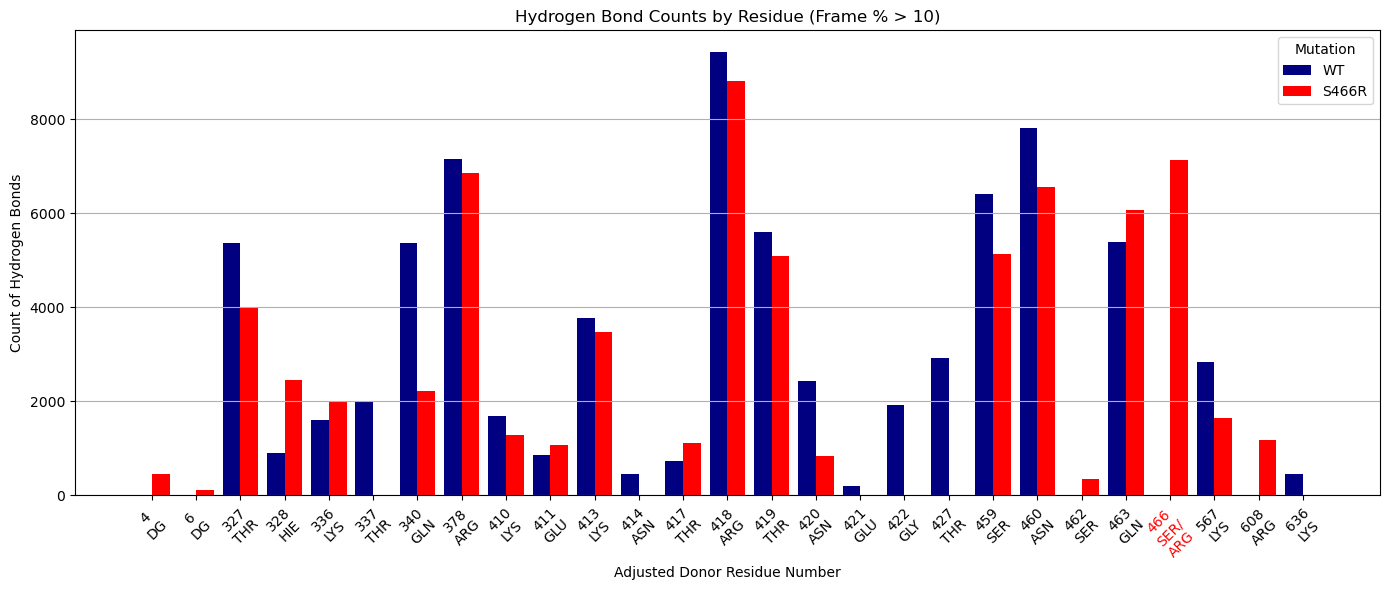

In [57]:
# Filter data for frame% > 10
filtered_df_S466R = combined_df_S466R[combined_df_S466R['frame%'] > 10]
filtered_df_wt = combined_df_wt[combined_df_wt['frame%'] > 10]

# Pivot the data to aggregate counts by donor_res_num_adjusted (no donor_chain)
pivot_df_S466R = pd.pivot_table(filtered_df_S466R, 
                                index='donor_res_num_adjusted',
                                values='count',
                                aggfunc='sum',  # Sum counts for duplicates
                                fill_value=0)   # Replace NaN with 0

pivot_df_wt = pd.pivot_table(filtered_df_wt, 
                             index='donor_res_num_adjusted',
                             values='count',
                             aggfunc='sum',  # Sum counts for duplicates
                             fill_value=0)   # Replace NaN with 0

# Align indices by taking the union of residue numbers
all_residues = sorted(set(pivot_df_S466R.index).union(set(pivot_df_wt.index)))
pivot_df_S466R = pivot_df_S466R.reindex(all_residues, fill_value=0)
pivot_df_wt = pivot_df_wt.reindex(all_residues, fill_value=0)

combined_df = pd.concat([filtered_df_wt, filtered_df_S466R], ignore_index=True)

res_name_map = (combined_df
    .drop_duplicates(subset='donor_res_num_adjusted')
    .set_index('donor_res_num_adjusted')['donor_res_name']
    .reindex(all_residues))

# x-axis labels
x_labels = [
    f"{num}\n{'SER/\nARG' if num == 466 else res_name_map.get(num, '')}"
    for num in all_residues
]

# Create the plot
plt.figure(figsize=(14, 6))

# Set bar width and positions
bar_width = 0.4  # Two bars (S466R and WT)
x = np.arange(len(all_residues))  # Positions for each donor residue

# Plot bars for S466R and WT
plt.bar(x - bar_width/2, 
        pivot_df_wt['count'], 
        color='navy',
        width=bar_width, 
        label='WT')
plt.bar(x + bar_width/2, 
        pivot_df_S466R['count'], 
        width=bar_width, 
        color='red',
        label='S466R')

# Customize the plot
plt.xlabel('Adjusted Donor Residue Number')
plt.ylabel('Count of Hydrogen Bonds')
plt.title('Hydrogen Bond Counts by Residue (Frame % > 10)')
plt.xticks(x, x_labels, rotation=45)
plt.grid(axis='y')
plt.legend(title='Mutation')
plt.tight_layout()

# Highlight mutated residue
mut_index = all_residues.index(466)
ax = plt.gca()  # get current axes
tick_labels = ax.get_xticklabels()
tick_labels[mut_index].set_color('red')

plt.show()

S466R has a high number of hydrogen bonds at the mutated residue, while WT has none. Conversely, hydrogen bond at residues 422 and 427 are present in WT but not in the mutant. In the 3D structure of the protein, 466 is located next to 427 and in the proximity of 422. The hypothesis is that the higher attraction of DNA towards the positive R displaces the hydrogen bonds towards the mutated residue.

Per chain

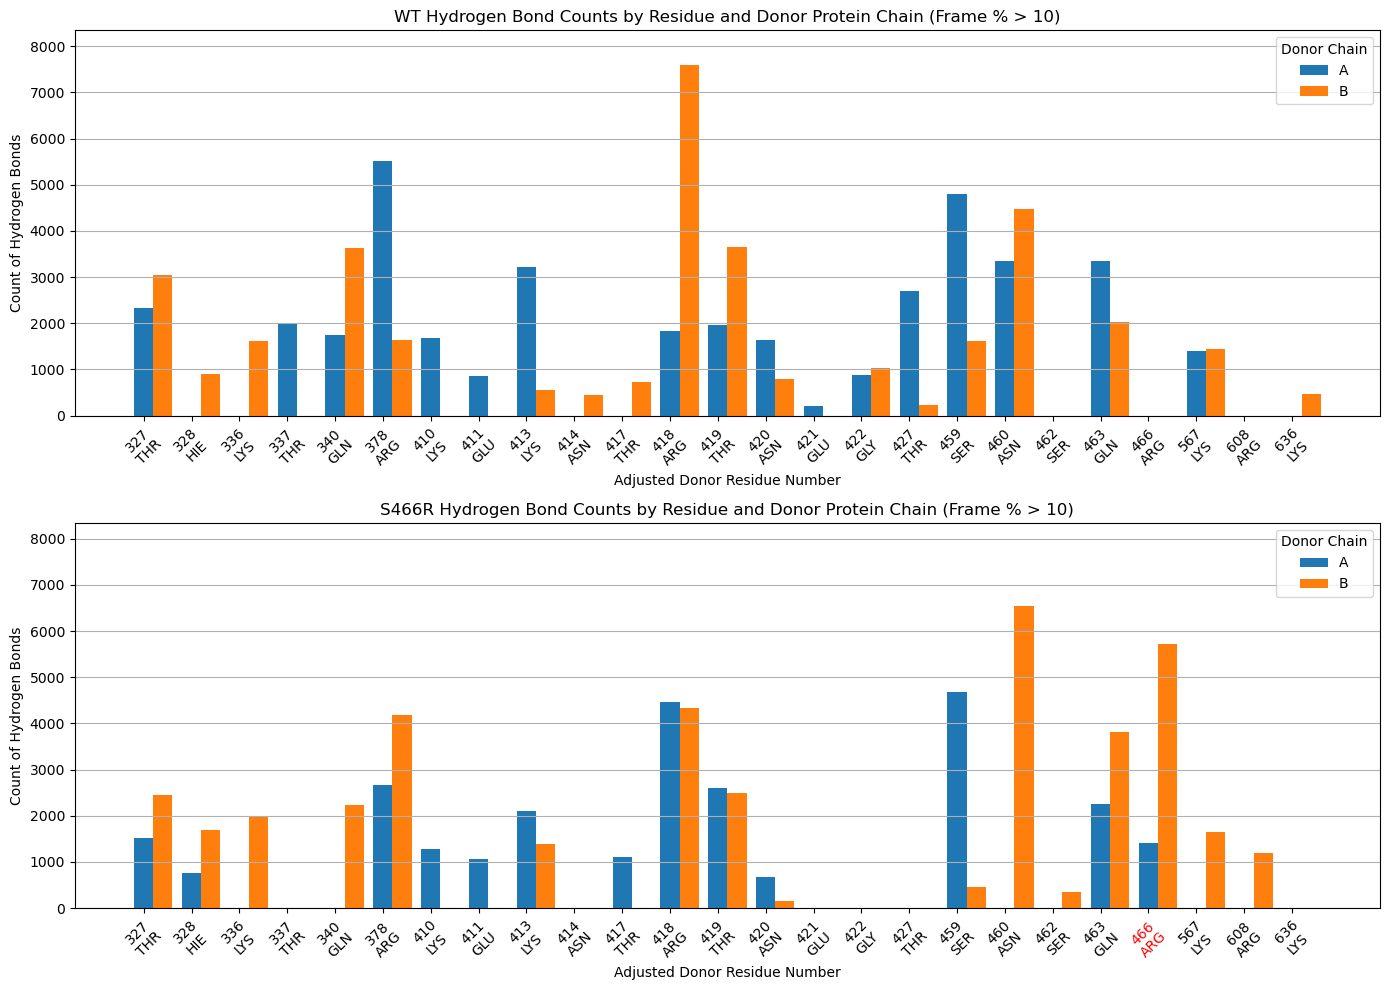

In [58]:
# Filter data for frame% > 10
filtered_df_wt = combined_df_wt[(combined_df_wt['frame%'] > 10) & ((combined_df_wt['donor_chain'] == 'A') | (combined_df_wt['donor_chain'] == 'B'))]
filtered_df_S466R = combined_df_S466R[(combined_df_S466R['frame%'] > 10) & ((combined_df_S466R['donor_chain'] == 'A') | (combined_df_S466R['donor_chain'] == 'B'))]

# Pivot the data with aggregation (sum) for duplicate entries
pivot_df_wt = pd.pivot_table(filtered_df_wt, 
                             index='donor_res_num_adjusted',
                             columns='donor_chain',
                             values='count',
                             aggfunc='sum',
                             fill_value=0)

pivot_df_S466R = pd.pivot_table(filtered_df_S466R, 
                                index='donor_res_num_adjusted',
                                columns='donor_chain',
                                values='count',
                                aggfunc='sum',
                                fill_value=0)

# Align indices by taking the union of residue numbers
all_residues = sorted(set(pivot_df_wt.index).union(set(pivot_df_S466R.index)))
pivot_df_wt = pivot_df_wt.reindex(all_residues, fill_value=0)
pivot_df_S466R = pivot_df_S466R.reindex(all_residues, fill_value=0)

# Create residue name mapping
combined_df = pd.concat([filtered_df_wt, filtered_df_S466R], ignore_index=True)
res_name_map = (combined_df
                .drop_duplicates(subset='donor_res_num_adjusted')
                .set_index('donor_res_num_adjusted')['donor_res_name']
                .reindex(all_residues)
                .fillna('Unknown'))


# Calculate joint y-axis limits
y_max = max(pivot_df_wt.values.max(), pivot_df_S466R.values.max())
y_min = min(pivot_df_wt.values.min(), pivot_df_S466R.values.min())
y_limits = [y_min, y_max * 1.1]  # Add 10% padding to max

# subplots (2 rows, 1 column)
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 10))

# Data for looping
datasets = [
    {'pivot_df': pivot_df_wt, 'ax': ax1, 'title': 'WT Hydrogen Bond Counts by Residue and Donor Protein Chain (Frame % > 10)'},
    {'pivot_df': pivot_df_S466R, 'ax': ax2, 'title': 'S466R Hydrogen Bond Counts by Residue and Donor Protein Chain (Frame % > 10)'}
]

# Plot
x = np.arange(len(all_residues))
for dataset in datasets:
    pivot_df = dataset['pivot_df']
    ax = dataset['ax']
    sections = pivot_df.columns
    n_sections = len(sections)
    bar_width = 0.8 / n_sections

    for i, section in enumerate(sections):
        ax.bar(x + i * bar_width, 
               pivot_df[section], 
               width=bar_width, 
               label=section,
               align='edge')
    
    ax.set_ylabel('Count of Hydrogen Bonds')
    ax.set_xlabel('Adjusted Donor Residue Number')
    ax.set_title(dataset['title'])
    ax.set_xticks(x + bar_width * (n_sections - 1) / 2)
    x_labels = [
        f"{num}\n{'ARG' if (ax == ax2 and num == 466) else res_name_map[num]}"
        for num in all_residues
    ]
    if ax == ax2:
        mut_index = all_residues.index(466)
        tick_labels = ax.get_xticklabels()
        tick_labels[mut_index].set_color('red')
    ax.set_xticklabels(x_labels, rotation=45)
    ax.set_ylim(y_limits)
    ax.grid(axis='y')
    ax.legend(title='Donor Chain')

plt.tight_layout()
plt.show()

### Protein as donor

**Frame %**

Text(0.5, 1.0, 'WT 466 Hydrogen Bond Frame % Distribution')

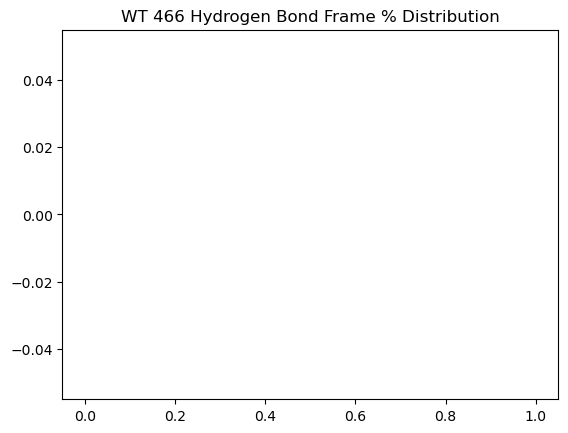

In [59]:
filtered_df = combined_df_wt[combined_df_wt['donor_res_num_adjusted'] == 466]
plt.hist(filtered_df['frame%'])
plt.title('WT 466 Hydrogen Bond Frame % Distribution')

Text(0.5, 1.0, 'S466R 466 Hydrogen Bond Frame % Distribution')

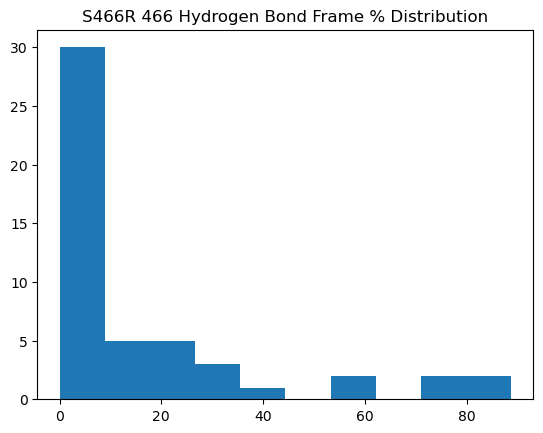

In [60]:
filtered_df = combined_df_S466R[combined_df_S466R['donor_res_num_adjusted'] == 466]
plt.hist(filtered_df['frame%'])
plt.title('S466R 466 Hydrogen Bond Frame % Distribution')

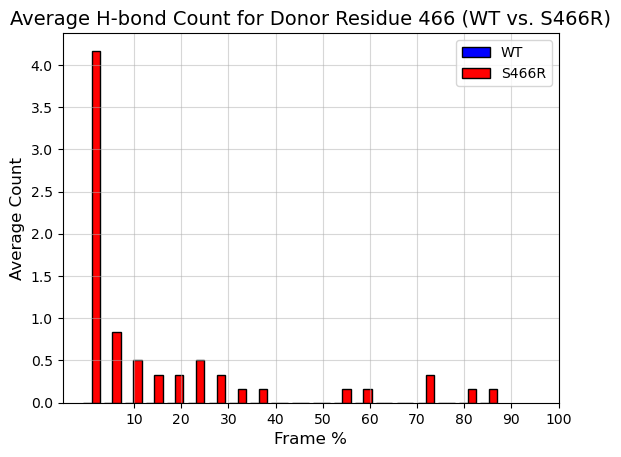

In [61]:
# Filter data
filtered_df_S466R = combined_df_S466R[combined_df_S466R['donor_res_num_adjusted'] == 466]
filtered_df_wt = combined_df_wt[combined_df_wt['donor_res_num_adjusted'] == 466]

# Common bins
bins = np.histogram(np.hstack((filtered_df_wt['frame%'], filtered_df_S466R['frame%'])), bins=20)[1]
wt_counts, wt_bins = np.histogram(filtered_df_wt['frame%'], bins=bins)
mut_counts, mut_bins = np.histogram(filtered_df_S466R['frame%'], bins=bins)

# Average counts by the number of replicates
avg_wt_counts = wt_counts / (len(wt_dfs) * 2)  # 2 methods (gmx and mda)
avg_mut_counts = mut_counts / (len(S466R_dfs) * 2)  # 2 methods (gmx and mda)

# Bar positions
bar_width = (bins[1] - bins[0]) * 0.4
wt_positions = bins[:-1]
mut_positions = bins[:-1] + bar_width

# Plot
plt.bar(wt_positions, avg_wt_counts, width=bar_width, color='blue', label='WT', edgecolor='black')
plt.bar(mut_positions, avg_mut_counts, width=bar_width, color='red', label='S466R', edgecolor='black')

# Customize
plt.xlabel('Frame %', fontsize=12)
plt.ylabel('Average Count', fontsize=12)  # Updated y-axis label
plt.title('Average H-bond Count for Donor Residue 466 (WT vs. S466R)', fontsize=14)  # Updated title
plt.xticks(np.arange(10, 101, 10))  # Ticks every 10%, starting from 10
plt.legend(fontsize=10)
plt.grid(True, alpha=0.5)

plt.show()

In [58]:
filtered_df_S466R.shape

(50, 19)

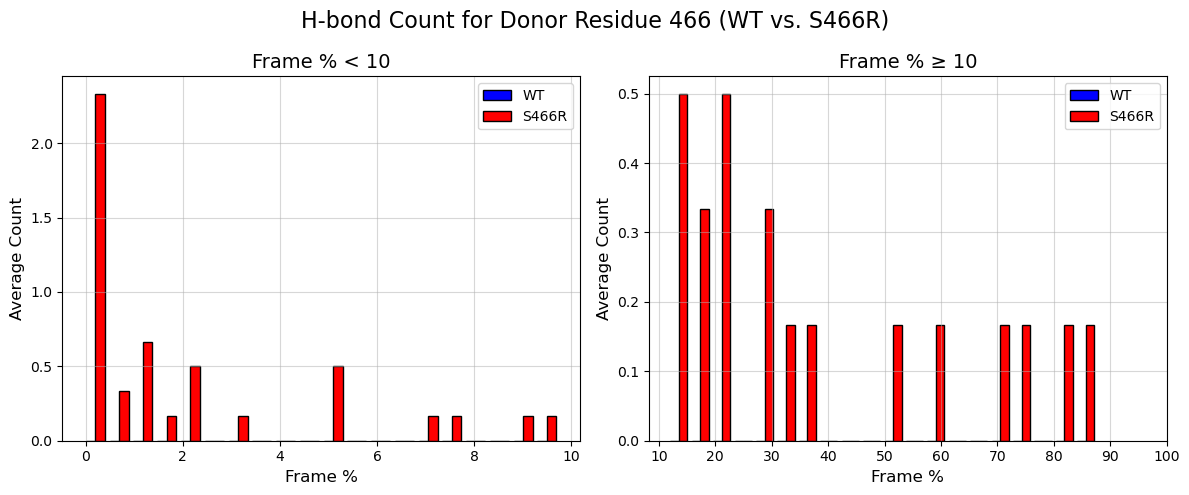

In [62]:

# Filter data
filtered_df_S466R = combined_df_S466R[combined_df_S466R['donor_res_num_adjusted'] == 466]
filtered_df_wt = combined_df_wt[combined_df_wt['donor_res_num_adjusted'] == 466]

# Split data into low (<10) and high (>=10) frame% values
wt_low = filtered_df_wt[filtered_df_wt['frame%'] < 10]['frame%']
wt_high = filtered_df_wt[filtered_df_wt['frame%'] >= 10]['frame%']
S466R_low = filtered_df_S466R[filtered_df_S466R['frame%'] < 10]['frame%']
S466R_high = filtered_df_S466R[filtered_df_S466R['frame%'] >= 10]['frame%']

# Create bins for low and high ranges
bins_low = np.histogram(np.hstack((wt_low, S466R_low)), bins=20)[1]
bins_high = np.histogram(np.hstack((wt_high, S466R_high)), bins=20)[1]

# Compute histogram counts
wt_counts_low, wt_bins_low = np.histogram(wt_low, bins=bins_low)
mut_counts_low, mut_bins_low = np.histogram(S466R_low, bins=bins_low)
wt_counts_high, wt_bins_high = np.histogram(wt_high, bins=bins_high)
mut_counts_high, mut_bins_high = np.histogram(S466R_high, bins=bins_high)

# Average counts by the number of replicates x number of methods
avg_wt_counts_low = wt_counts_low / (len(wt_dfs) * 2) 
avg_mut_counts_low = mut_counts_low / (len(S466R_dfs) * 2) 
avg_wt_counts_high = wt_counts_high / (len(wt_dfs) * 2) 
avg_mut_counts_high = mut_counts_high / (len(S466R_dfs) * 2) 

# Set up bar positions
bar_width_low = (bins_low[1] - bins_low[0]) * 0.4
bar_width_high = (bins_high[1] - bins_high[0]) * 0.4
wt_positions_low = bins_low[:-1]
mut_positions_low = bins_low[:-1] + bar_width_low
wt_positions_high = bins_high[:-1]
mut_positions_high = bins_high[:-1] + bar_width_high

# Create subplots
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5), sharey=False)

# Plot low frame% (<10)
ax1.bar(wt_positions_low, avg_wt_counts_low, width=bar_width_low, color='blue', label='WT', edgecolor='black')
ax1.bar(mut_positions_low, avg_mut_counts_low, width=bar_width_low, color='red', label='S466R', edgecolor='black')
ax1.set_xlabel('Frame %', fontsize=12)
ax1.set_ylabel('Average Count', fontsize=12)
ax1.set_title('Frame % < 10', fontsize=14)
ax1.legend(fontsize=10)
ax1.grid(True, alpha=0.5)
ax1.set_xticks(np.arange(0, 11, 2)) 

# Plot high frame% (>=10)
ax2.bar(wt_positions_high, avg_wt_counts_high, width=bar_width_high, color='blue', label='WT', edgecolor='black')
ax2.bar(mut_positions_high, avg_mut_counts_high, width=bar_width_high, color='red', label='S466R', edgecolor='black')
ax2.set_xlabel('Frame %', fontsize=12)
ax2.set_ylabel('Average Count', fontsize=12)
ax2.set_title('Frame % ≥ 10', fontsize=14)
ax2.legend(fontsize=10)
ax2.grid(True, alpha=0.5)
ax2.set_xticks(np.arange(10, 101, 10))  # Ticks every 10%, starting from 10

# Adjust layout and save
plt.suptitle('H-bond Count for Donor Residue 466 (WT vs. S466R)', fontsize=16)
plt.tight_layout()

In [60]:
filtered_df_S466R.shape

(50, 19)

Neighbouring residues

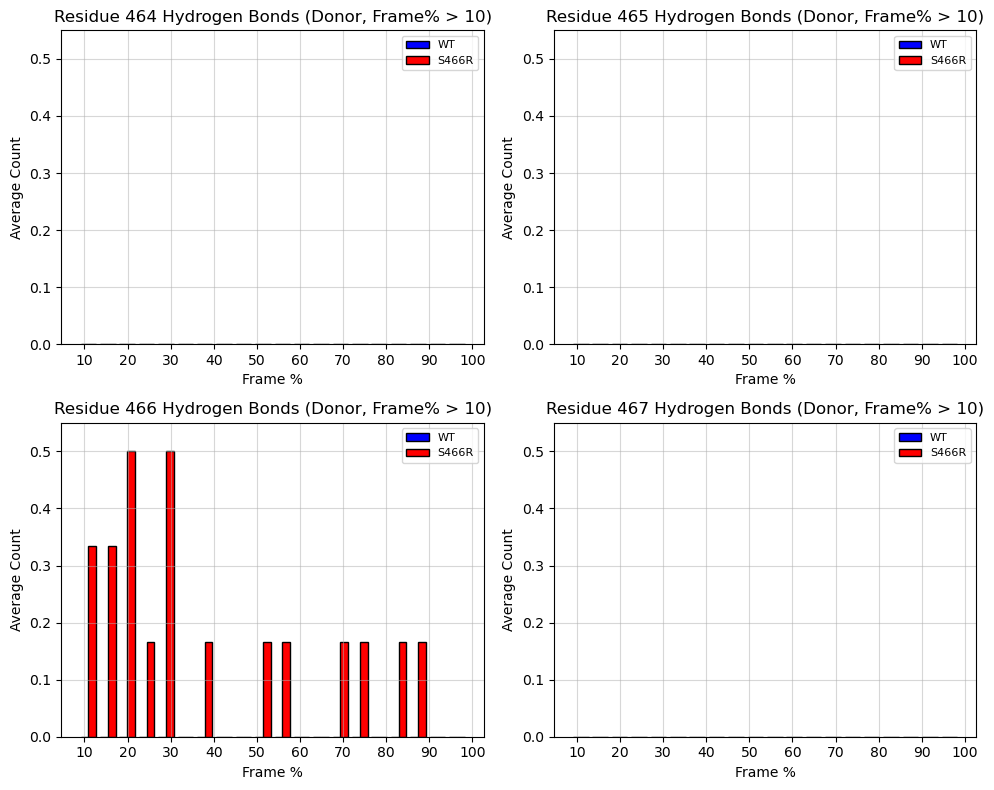

In [63]:

# Residues to plot
residues = [464, 465, 466, 467]

# Initialize a variable to track the maximum y-value
max_y_value = 0

# First pass: Calculate the maximum y-value across all residues
for residue in residues:
    # Filter data for the current residue and frame% > 10
    filtered_df_S466R = combined_df_S466R[(combined_df_S466R['donor_res_num_adjusted'] == residue) & (combined_df_S466R['frame%'] > 10)]
    filtered_df_wt = combined_df_wt[(combined_df_wt['donor_res_num_adjusted'] == residue) & (combined_df_wt['frame%'] > 10)]

    wt_counts, _ = np.histogram(filtered_df_wt['frame%'], bins=bins)
    mut_counts, _ = np.histogram(filtered_df_S466R['frame%'], bins=bins)

    # Average counts by the number of replicates x number of methods
    avg_wt_counts = wt_counts / (len(wt_dfs) * 2) 
    avg_mut_counts = mut_counts / (len(S466R_dfs) * 2) 

    # Update the maximum y-value
    max_y_value = max(max_y_value, max(avg_wt_counts), max(avg_mut_counts))

# Second pass: Plot the data
fig, axes = plt.subplots(2, 2, figsize=(10, 8))
axes = axes.flatten()  # Flatten the 2D array of axes for easier indexing

for i, residue in enumerate(residues):
    # Filter data for the current residue and frame% > 10
    filtered_df_S466R = combined_df_S466R[(combined_df_S466R['donor_res_num_adjusted'] == residue) & (combined_df_S466R['frame%'] > 10)]
    filtered_df_wt = combined_df_wt[(combined_df_wt['donor_res_num_adjusted'] == residue) & (combined_df_wt['frame%'] > 10)]

    # Common bins
    bins = np.linspace(10, 100, 21)  # 21 edges for 20 bins
    wt_counts, _ = np.histogram(filtered_df_wt['frame%'], bins=bins)
    mut_counts, _ = np.histogram(filtered_df_S466R['frame%'], bins=bins)

    # Average counts by the number of replicates x number of methods
    avg_wt_counts = wt_counts / (len(wt_dfs) * 2) 
    avg_mut_counts = mut_counts / (len(S466R_dfs) * 2) 

    # Bar positions
    bar_width = (bins[1] - bins[0]) * 0.4
    wt_positions = bins[:-1]
    mut_positions = bins[:-1] + bar_width

    # Plot on the current subplot
    axes[i].bar(wt_positions, avg_wt_counts, width=bar_width, color='blue', label='WT', edgecolor='black')
    axes[i].bar(mut_positions, avg_mut_counts, width=bar_width, color='red', label='S466R', edgecolor='black')

    # Customize the subplot
    axes[i].set_xlabel('Frame %', fontsize=10)
    axes[i].set_ylabel('Average Count', fontsize=10)
    axes[i].set_title(f'Residue {residue} Hydrogen Bonds (Donor, Frame% > 10)', fontsize=12)
    axes[i].set_xticks(np.arange(10, 101, 10))  # Ticks every 10%, starting from 10
    axes[i].set_ylim(0, max_y_value * 1.1)  # Use the same y-axis range for all plots
    axes[i].grid(True, alpha=0.5)
    axes[i].legend(fontsize=8)

# Remove any unused subplot (if fewer than 6 residues)
for j in range(len(residues), len(axes)):
    fig.delaxes(axes[j])

# Adjust layout
plt.tight_layout()
plt.show()

Bonds where residue 466 is the donor and frame % > 10.

In [62]:
combined_df_S466R[(combined_df_S466R['donor_res_num_adjusted'] == 466) & (combined_df_S466R['frame%'] > 10)].shape

(18, 19)

In [63]:
combined_df_S466R[(combined_df_S466R['donor_res_num_adjusted'] == 466) & (combined_df_S466R['frame%'] > 10)].sort_values('frame%', ascending=False).head(10)

,donor,hydrogen,acceptor,count,frame%,donor_res_name,donor_res_num,donor_atom_name,donor_chain,acceptor_res_name,acceptor_res_num,acceptor_atom_name,acceptor_chain,donor_type,acceptor_type,donor_res_num_adjusted,acceptor_res_num_adjusted,donor_section,acceptor_section
158,14902,14904,19737,888,88.711289,ARG,331,NH1,B,DA,6,OP1,D,protein,DNA,466,6,DBD,backbone
174,14902,14904,19737,838,83.716284,ARG,331,NH1,B,DA,6,OP1,D,protein,DNA,466,6,DBD,backbone
198,14905,14906,19770,742,74.125874,ARG,331,NH2,B,DT,7,OP2,D,protein,DNA,466,7,DBD,backbone
196,14905,14906,19770,721,72.027972,ARG,331,NH2,B,DT,7,OP2,D,protein,DNA,466,7,DBD,backbone
179,14905,14907,19739,590,58.941059,ARG,331,NH2,B,DA,6,O5',D,protein,DNA,466,6,DBD,backbone
162,14905,14907,19738,543,54.245754,ARG,331,NH2,B,DA,6,OP2,D,protein,DNA,466,6,DBD,backbone
178,14905,14907,19738,389,38.861139,ARG,331,NH2,B,DA,6,OP2,D,protein,DNA,466,6,DBD,backbone
84,5479,5481,19043,320,31.968032,ARG,331,NH2,A,DT,7,OP2,C,protein,DNA,466,7,DBD,backbone
83,5479,5481,19043,297,29.670330,ARG,331,NH2,A,DT,7,OP2,C,protein,DNA,466,7,DBD,backbone
82,5476,5478,19043,288,28.771229,ARG,331,NH1,A,DT,7,OP2,C,protein,DNA,466,7,DBD,backbone


Acceptor residue sections. Are the hydrogen bonds happening with the DNA backbone or the bases?

In [64]:
def process_residue_data(residue, df, replicates):
    filtered_df = df[(df['donor_res_num_adjusted'] == residue) & (df['frame%'] > 10)]
    base = filtered_df[filtered_df['acceptor_section'] == 'base']
    backbone = filtered_df[filtered_df['acceptor_section'] == 'backbone']
    fixed_bins = np.linspace(10, 100, 21)  # 21 edges for 20 bins
    base_counts, _ = np.histogram(base['frame%'], bins=fixed_bins)
    backbone_counts, _ = np.histogram(backbone['frame%'], bins=fixed_bins)
    norm_base = base_counts / (replicates * 2) 
    norm_backbone = backbone_counts / (replicates * 2) 
    return norm_base, norm_backbone, fixed_bins

/tmp/ipykernel_1003286/13100774.py:19: UserWarning: Attempting to set identical low and high ylims makes transformation singular; automatically expanding.
  axes[i].set_ylim(0, max_y_value * 1.1)


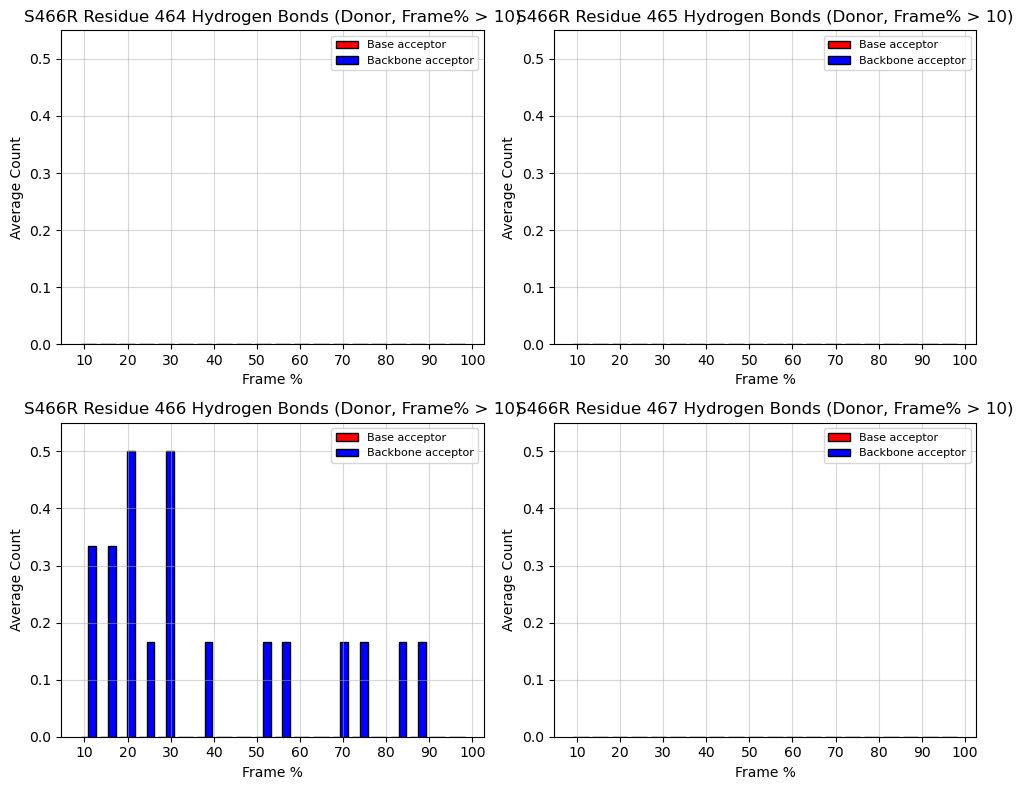

In [65]:
residues = [464, 465, 466, 467]
max_y_value = 0
fig, axes = plt.subplots(2, 2, figsize=(10, 8), sharey=True)
axes = axes.flatten()

for i, residue in enumerate(residues):
    norm_base, norm_backbone, bins = process_residue_data(residue, combined_df_S466R, len(S466R_dfs))
    max_y_value = max(max_y_value, max(norm_base), max(norm_backbone))

    bar_width = (bins[1] - bins[0]) * 0.4
    axes[i].bar(bins[:-1], norm_base, width=bar_width, color='red', label='Base acceptor', edgecolor='black')
    axes[i].bar(bins[:-1] + bar_width, norm_backbone, width=bar_width, color='blue', label='Backbone acceptor', edgecolor='black')

    axes[i].set_xlabel('Frame %', fontsize=10)
    axes[i].set_ylabel('Average Count', fontsize=10)
    axes[i].set_title(f'S466R Residue {residue} Hydrogen Bonds (Donor, Frame% > 10)', fontsize=12)
    axes[i].set_xticks(np.arange(10, 101, 10))
    axes[i].tick_params(axis='y', labelleft=True)
    axes[i].set_ylim(0, max_y_value * 1.1)
    axes[i].grid(True, alpha=0.5)
    axes[i].legend(fontsize=8)

for j in range(len(residues), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

**DNA residues binding to residue 466**

Note that these bonds are NOT filtered fo frame % > 10. There are no hbonds at reidue 466 in the WT, so only mutant S466R is analyzed.

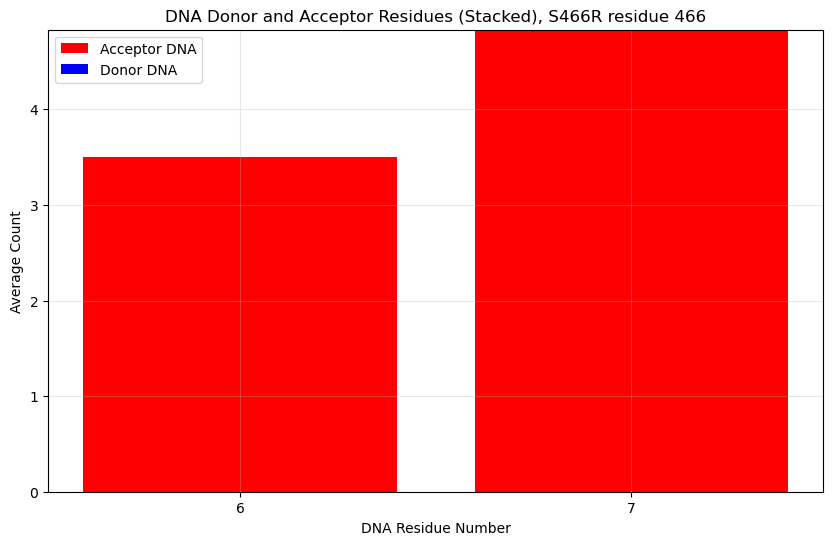

In [67]:
donor_S466R = combined_df_S466R[combined_df_S466R['donor_res_num_adjusted'] == 466]
acceptor_S466R = combined_df_S466R[combined_df_S466R['acceptor_res_num_adjusted'] == 466]

donor_counts = donor_S466R['acceptor_res_num_adjusted'].value_counts().sort_index()
acceptor_counts = acceptor_S466R['donor_res_num_adjusted'].value_counts().sort_index()

plt.figure(figsize=(10, 6))

# Get all unique residue numbers
all_res_nums = sorted(set(donor_counts.index).union(acceptor_counts.index))

# Align the counts, filling with 0 where no data exists
donor_values = [donor_counts.get(num, 0) / (len(S466R_dfs) * 2)  for num in all_res_nums]
acceptor_values = [acceptor_counts.get(num, 0) / (len(S466R_dfs) * 2) for num in all_res_nums]

# Create stacked bar plot
plt.bar(all_res_nums, donor_values, color='red', label='Acceptor DNA')
plt.bar(all_res_nums, acceptor_values, bottom=donor_values, color='blue', label='Donor DNA')

# Set x-ticks for every unit
min_residue = min(all_res_nums)
max_residue = max(all_res_nums)
plt.xticks(range(int(min_residue), int(max_residue) + 1, 1))

plt.xlabel('DNA Residue Number')
plt.ylabel('Average Count')
plt.title('DNA Donor and Acceptor Residues (Stacked), S466R residue 466')
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()


In [68]:
def plot_interactions(ax, df_donor, df_acceptor, section, title, replicates):
    # Filter for section
    donor = df_donor[df_donor['acceptor_section'] == section]
    acceptor = df_acceptor[df_acceptor['donor_section'] == section]
    
    # Count occurrences
    donor_counts = donor['acceptor_res_num_adjusted'].value_counts().sort_index()
    acceptor_counts = acceptor['donor_res_num_adjusted'].value_counts().sort_index()
    
    # Define all residue numbers (1 to 23, based on DNA strands)
    all_res_nums = list(range(1, 24))  # Residues 1 to 23 inclusive
    
    # Normalize counts, using 0 for residues with no counts
    donor_values = [donor_counts.get(num, 0) / (replicates * 2) for num in all_res_nums]
    acceptor_values = [acceptor_counts.get(num, 0) / (replicates * 2) for num in all_res_nums]
    
    # Create stacked bar plot
    ax.bar(all_res_nums, donor_values, color='red', label='Acceptor DNA')
    ax.bar(all_res_nums, acceptor_values, bottom=donor_values, color='blue', label='Donor DNA')
    
    # Set x-ticks to include all residues (1 to 23)
    ax.set_xticks(all_res_nums)
    ax.tick_params(axis='x', rotation=45)
    
    # Customize plot
    ax.set_xlabel('DNA Residue Number')
    ax.set_title(title)
    ax.grid(True, alpha=0.3)
    ax.legend()

In [69]:
# Define the DNA strands
strand1 = "CGACAGTTTCCCGGAAATGCAGC"  # Chain C, 23 nucleotides
strand2 = "GCTGCATTTCCGGGAAACTGTCG"  # Chain D, 23 nucleotides

# Create a mapping of residue numbers to nucleotide pairs
residue_to_nucleotides = {i+1: (strand1[i], strand2[i]) for i in range(23)}

# Consensus residues
consensus_residues = [8, 9, 10, 11, 13, 14, 15, 16]

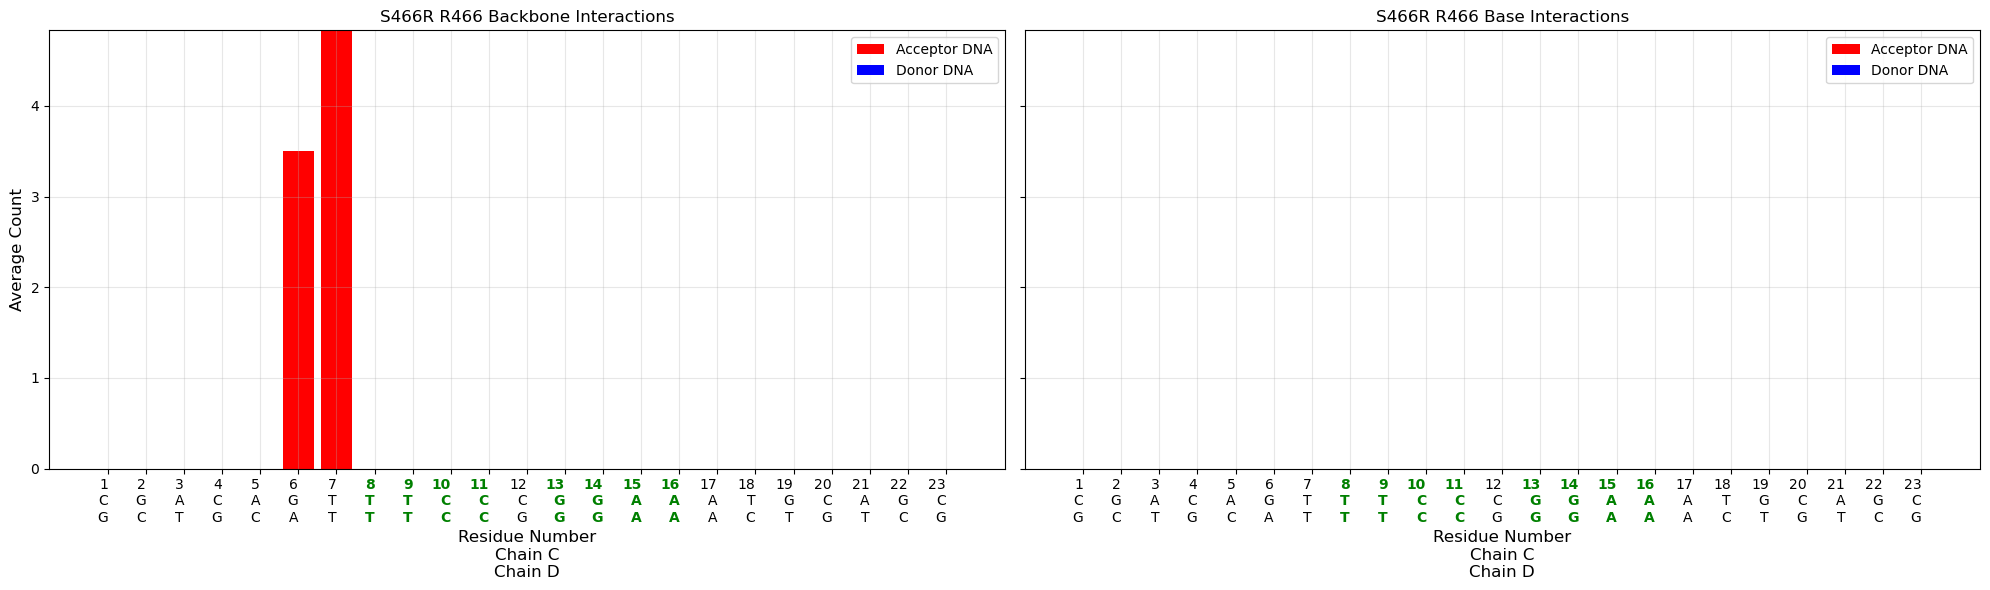

In [70]:
# Filter data for donor and acceptor at residue 466
donor_S466R = combined_df_S466R[combined_df_S466R['donor_res_num_adjusted'] == 466]
acceptor_S466R = combined_df_S466R[combined_df_S466R['acceptor_res_num_adjusted'] == 466]

# Create figure with two subplots
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(20, 6), sharey=True)
ax1.set_ylabel('Average Count', fontsize=12)

# Plot backbone and base interactions (assuming plot_interactions is defined)
plot_interactions(ax1, donor_S466R, acceptor_S466R, 'backbone', 'S466R R466 Backbone Interactions', len(S466R_dfs))
plot_interactions(ax2, donor_S466R, acceptor_S466R, 'base', 'S466R R466 Base Interactions', len(S466R_dfs))

# Customize x-axis labels to include residue number, Chain C nucleotide, and Chain D nucleotide
for ax in [ax1, ax2]:
    # Get current x-ticks (assuming they are residue numbers)
    ticks = ax.get_xticks()
    # Filter ticks to ensure they are within the residue range (1-23)
    valid_ticks = [int(t) for t in ticks if t.is_integer() and 1 <= t <= 23]
    # Create labels: residue number, Chain C nucleotide, Chain D nucleotide
    labels = [f"{res}\n{residue_to_nucleotides.get(res, ('N/A', 'N/A'))[0]}\n{residue_to_nucleotides.get(res, ('N/A', 'N/A'))[1]}" 
              for res in valid_ticks]
    ax.set_xticks(valid_ticks)
    ax.set_xticklabels(labels, fontsize=10, rotation=0, ha='right', va='top')

    # Color consensus sequence residues green
    for i, label in enumerate(ax.get_xticklabels()):
        if valid_ticks[i] in consensus_residues:
            label.set_color('green')
            label.set_weight('bold')
                
    ax.set_xlabel('Residue Number\nChain C\nChain D', fontsize=12)

# Adjust layout to prevent label clipping
plt.tight_layout()
plt.show()

Looking at residues 427, 422, 421 in WT.

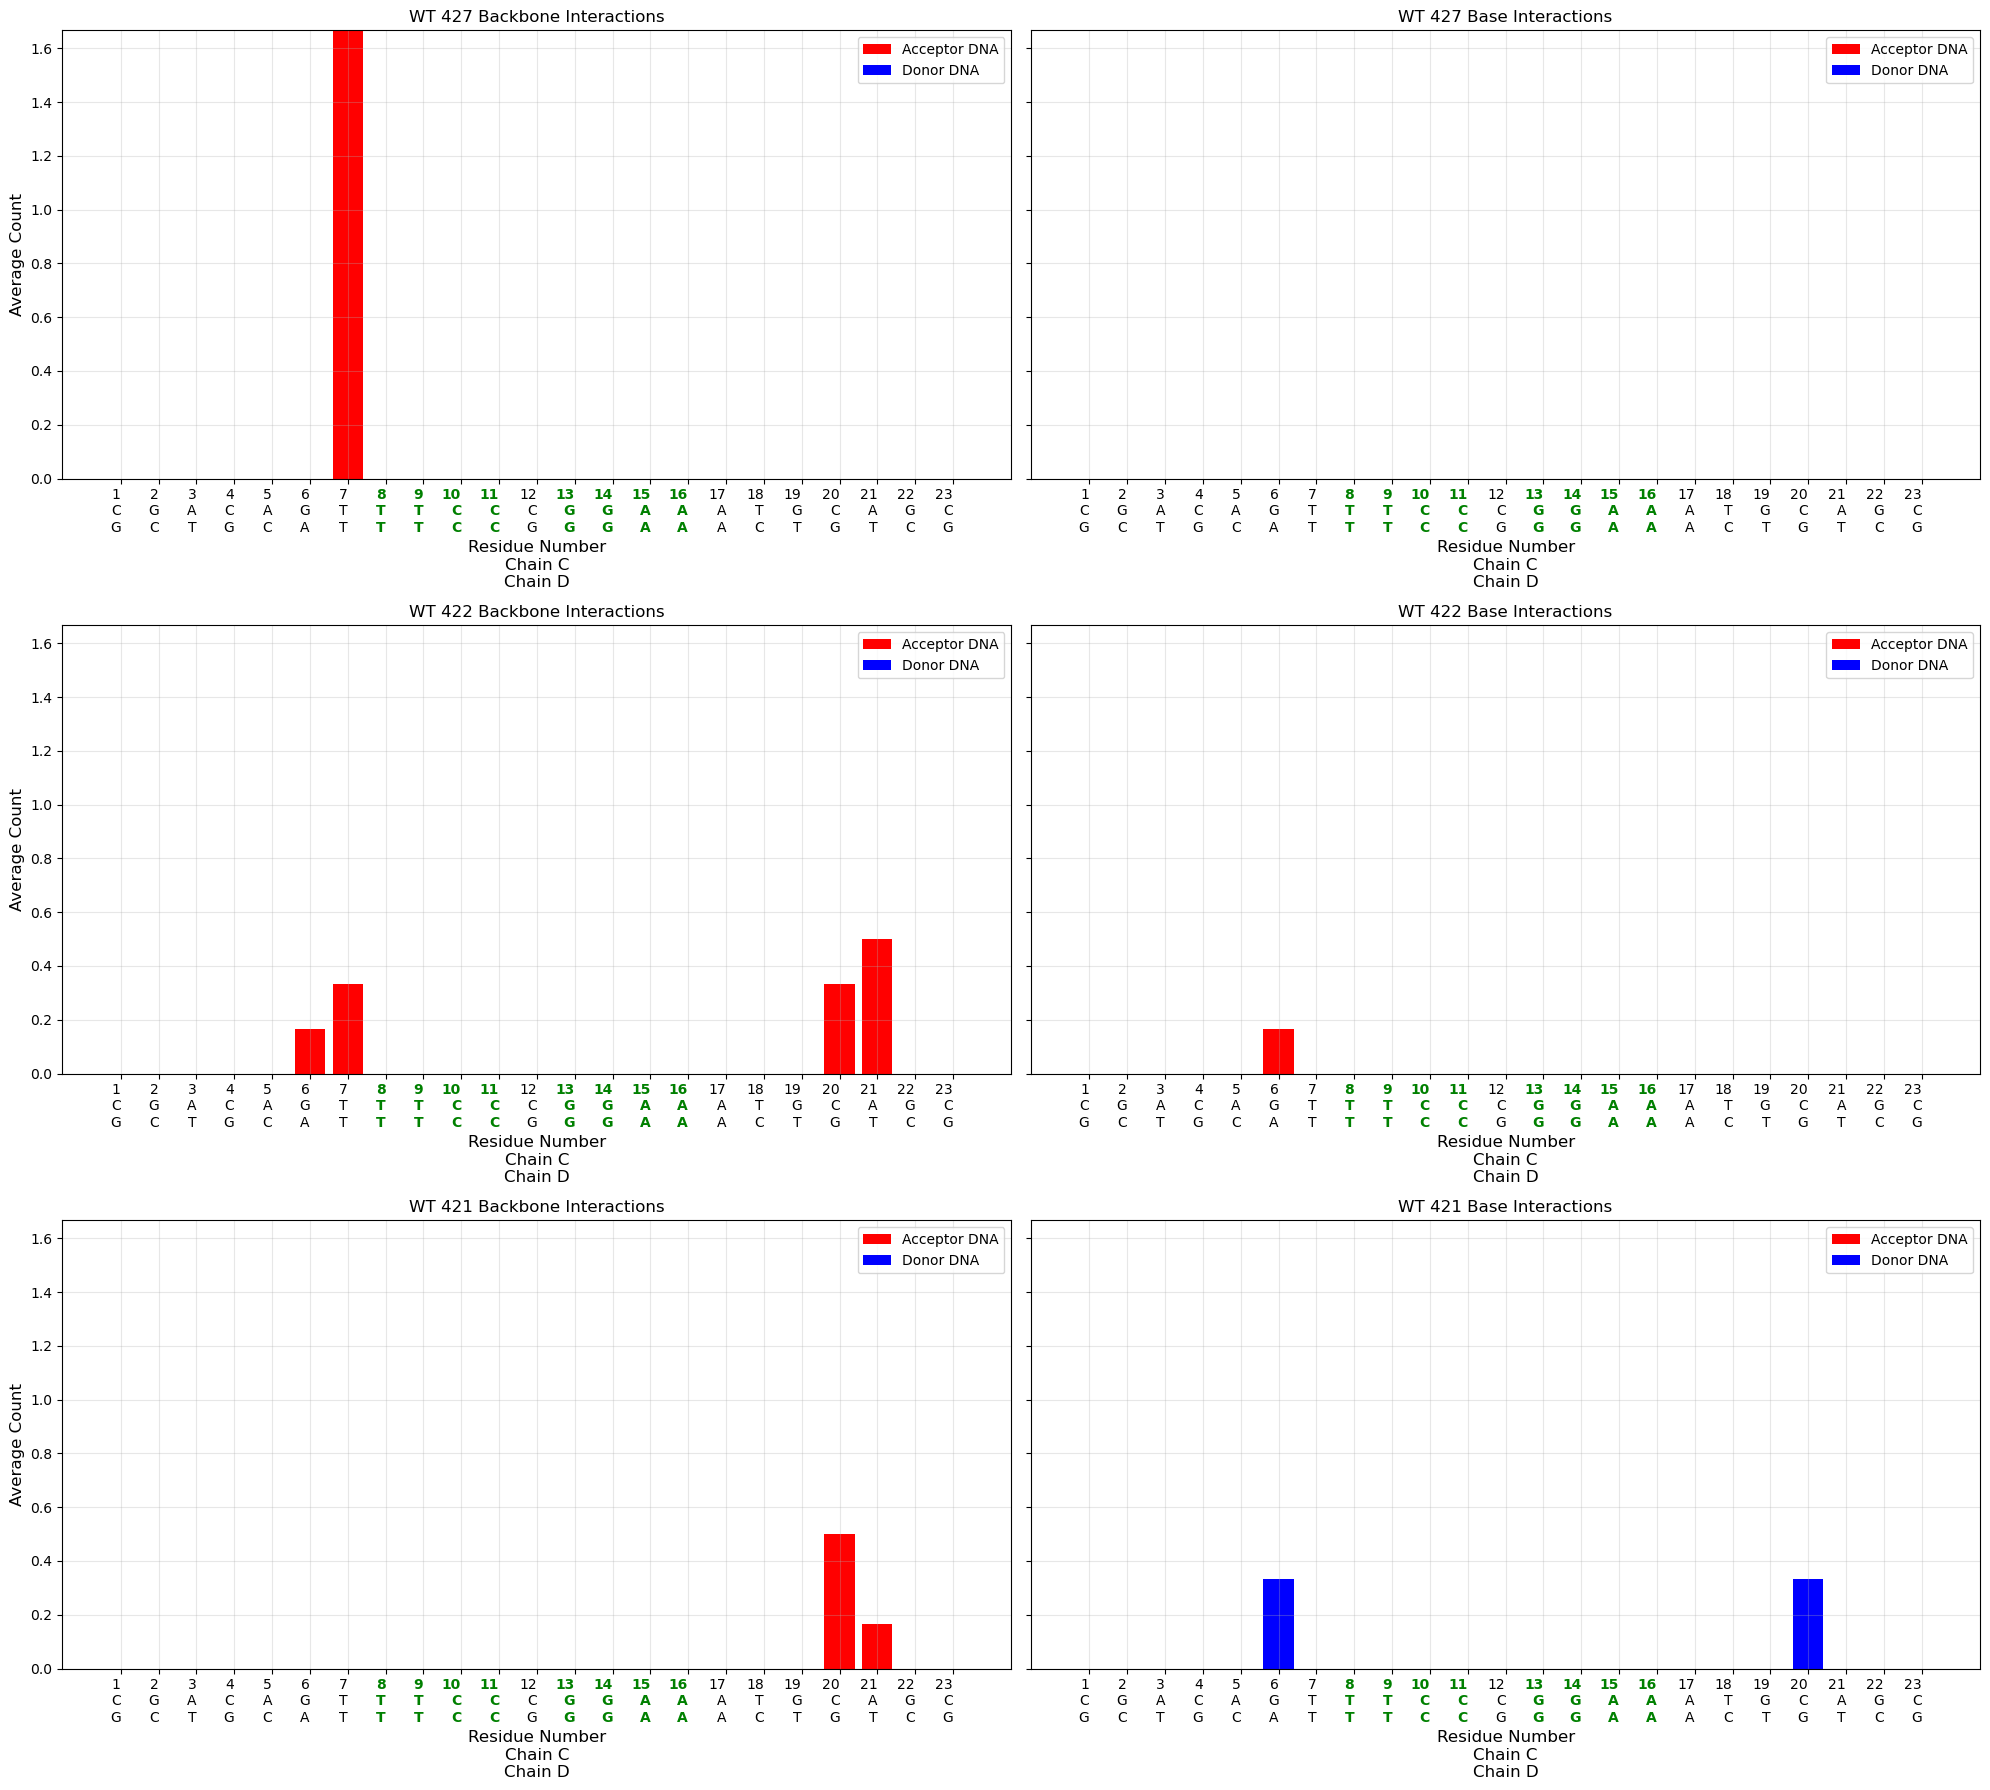

In [72]:
# Define the residues to plot
residues = [427, 422, 421]

# Create figure with three rows and two columns
fig, axes = plt.subplots(3, 2, figsize=(20, 18), sharey=True)

# Set y-label for the left column only
for i in range(3):
    axes[i, 0].set_ylabel(f'Average Count', fontsize=12)

# Iterate over residues to create plots
for i, res in enumerate(residues):
    # Filter data for donor and acceptor at the current residue
    donor_wt = combined_df_wt[combined_df_wt['donor_res_num_adjusted'] == res]
    acceptor_wt = combined_df_wt[combined_df_wt['acceptor_res_num_adjusted'] == res]

    # Plot backbone and base interactions (assuming plot_interactions is defined)
    plot_interactions(axes[i, 0], donor_wt, acceptor_wt, 'backbone', f'WT {res} Backbone Interactions', len(wt_dfs))
    plot_interactions(axes[i, 1], donor_wt, acceptor_wt, 'base', f'WT {res} Base Interactions', len(wt_dfs))

    # Customize x-axis labels for both subplots in the row
    for ax in [axes[i, 0], axes[i, 1]]:
        # Get current x-ticks (assuming they are residue numbers)
        ticks = ax.get_xticks()
        # Filter ticks to ensure they are within the residue range (1-23)
        valid_ticks = [int(t) for t in ticks if t.is_integer() and 1 <= t <= 23]
        # Create labels: residue number, Chain C nucleotide, Chain D nucleotide
        labels = [f"{res}\n{residue_to_nucleotides.get(res, ('N/A', 'N/A'))[0]}\n{residue_to_nucleotides.get(res, ('N/A', 'N/A'))[1]}" 
                  for res in valid_ticks]
        ax.set_xticks(valid_ticks)
        ax.set_xticklabels(labels, fontsize=10, rotation=0, ha='right', va='top')

        # Color consensus sequence residues green
        for i, label in enumerate(ax.get_xticklabels()):
            if valid_ticks[i] in consensus_residues:
                label.set_color('green')
                label.set_weight('bold')
                
        ax.set_xlabel('Residue Number\nChain C\nChain D', fontsize=12)

# Adjust layout to prevent label clipping
plt.tight_layout()
plt.show()

### Statistical test (Mann-Whitney)

In [82]:
from scipy.stats import mannwhitneyu, ttest_ind

In [83]:
# Aggregate hbond counts for each unique hbond across replicates or methods
def aggregate_hbonds(df_list, label):
    combined = pd.concat(df_list)
    agg_df = combined.groupby(['donor', 'acceptor', 'donor_res_num_adjusted', 
                               'acceptor_res_num_adjusted'])['count'].sum().reset_index()
    agg_df['group'] = label
    return agg_df

wt_agg = aggregate_hbonds(wt_dfs_flat, 'wt')
mut_agg = aggregate_hbonds(S466R_dfs_flat, 'S466R')

# Merge WT and MUT aggregated data
all_hbonds = pd.concat([wt_agg, mut_agg])

In [84]:
all_hbonds.head()

,donor,acceptor,donor_res_num_adjusted,acceptor_res_num_adjusted,count,group
0,3216,19869,327,11,30,wt
1,3216,19870,327,11,553,wt
2,3216,19871,327,11,2,wt
3,3216,19897,327,11,5,wt
4,3216,19899,327,12,195,wt


In [85]:
# Pivot table to compare WT and MUT (unchanged)
pivot_df = all_hbonds.pivot_table(index=['donor', 'acceptor', 'donor_res_num_adjusted', 
                               'acceptor_res_num_adjusted'], 
                                  columns='group', values='count', fill_value=0)
pivot_df['diff'] = pivot_df['S466R'] - pivot_df['wt']

# Aggregate WT counts across replicates
wt_counts_by_rep = [df.groupby(['donor', 'acceptor', 'donor_res_num_adjusted', 
                               'acceptor_res_num_adjusted'])['count'].sum() for df in wt_dfs_flat]
wt_counts_df = pd.concat(wt_counts_by_rep, axis=1).fillna(0)
wt_counts_df.columns = [f'rep{i+1}' for i in range(len(wt_dfs_flat))]
wt_mean = wt_counts_df.mean(axis=1)
wt_std = wt_counts_df.std(axis=1)

# Aggregate MUT counts
mut_counts = mut_agg.groupby(['donor', 'acceptor', 'donor_res_num_adjusted', 
                               'acceptor_res_num_adjusted'])['count'].sum()

# Create a common index to avoid KeyErrors
common_index = wt_counts_df.index.union(mut_counts.index)

# Reindex both WT and MUT data to the common index
wt_counts_df = wt_counts_df.reindex(common_index, fill_value=0)
wt_mean = wt_counts_df.mean(axis=1)
wt_std = wt_counts_df.std(axis=1)
mut_counts = mut_counts.reindex(common_index, fill_value=0)

# Build comparison DataFrame
comparison_df = pd.DataFrame({
    'WT_mean': wt_mean,
    'WT_std': wt_std,
    'MUT': mut_counts
}).fillna(0)

# Modified compare_groups function to handle missing indices
def compare_groups(row):
    hbond_idx = row.name  # Multi-index tuple
    if hbond_idx in wt_counts_df.index:
        wt_vals = wt_counts_df.loc[hbond_idx].values  # Values across replicates
    else:
        wt_vals = np.zeros(4)  # If hbond not in WT, assume zero counts
    mut_val = row['MUT']
    if np.all(wt_vals == 0) and mut_val == 0:
        return np.nan
    # Use Mann-Whitney U test
    stat, pval = mannwhitneyu(wt_vals, [mut_val] * 4, alternative='two-sided')
    return pval

# Apply statistical test
comparison_df['p_value'] = comparison_df.apply(compare_groups, axis=1)

# Filter for significant differences
#significant_diff = comparison_df[comparison_df['p_value'] < 0.05]
significant_diff = comparison_df
print("Significant differences between WT and MUT:")

Significant differences between WT and MUT:


In [86]:
# Apply the compare_groups function to each row
comparison_df['p_value'] = comparison_df.apply(compare_groups, axis=1)

# Filter for significant differences (p-value < 0.05)
significant_diff = comparison_df[comparison_df['p_value'] < 0.05]

In [87]:
significant_diff.shape

(467, 4)

In [88]:
significant_diff.head(20)

WT_mean  \
donor acceptor donor_res_num_adjusted acceptor_res_num_adjusted              
3216  19866    327                    10                          0.000000   
      19893    327                    10                          0.000000   
      19895    327                    11                          0.000000   
      19896    327                    11                          0.000000   
      19897    327                    11                          0.833333   
      19923    327                    11                          0.000000   
      19925    327                    12                          0.000000   
      19926    327                    12                          0.000000   
3231  19896    328                    11                          0.000000   
      19900    328                    12                         18.833333   
      19925    328                    12                          0.000000   
      19926    328                    12                          0.000000   
3376  19896    336                    11                          0.000000   
      19926    336                    12                          0.000000   
      19972    336                    13                          0.000000   
      19975    336                    13                          0.000000   
      20008    336                    14                          0.000000   
3392  19107    337                    9                           0.000000   
3431  19865    340                    10                          0.000000   
      19866    340                    10                          0.000000   

                                                                    WT_std  \
donor acceptor donor_res_num_adjusted acceptor_res_num_adjusted              
3216  19866    327                    10                          0.000000   
      19893    327                    10                          0.000000   
      19895    327                    11                          0.000000   
      19896    327                    11                          0.000000   
      19897    327                    11                          1.329160   
      19923    327                    11                          0.000000   
      19925    327                    12                          0.000000   
      19926    327                    12                          0.000000   
3231  19896    328                    11                          0.000000   
      19900    328                    12                         14.005951   
      19925    328                    12                          0.000000   
      19926    328                    12                          0.000000   
3376  19896    336                    11                          0.000000   
      19926    336                    12                          0.000000   
      19972    336                    13                          0.000000   
      19975    336                    13                          0.000000   
      20008    336                    14                          0.000000   
3392  19107    337                    9                           0.000000   
3431  19865    340                    10                          0.000000   
      19866    340                    10                          0.000000   

                                                                 MUT   p_value  
donor acceptor donor_res_num_adjusted acceptor_res_num_adjusted                 
3216  19866    327                    10                           4  0.004040  
      19893    327                    10                           1  0.004040  
      19895    327                    11                         307  0.004040  
      19896    327                    11                         845  0.004040  
      19897    327                    11                          80  0.008911  
      19923    327                    11                          

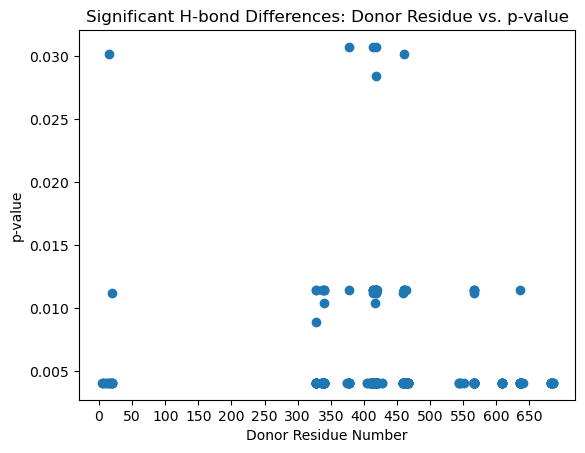

In [89]:
# Extract donor_res_num_adjusted from the multi-index
donor_res_nums = significant_diff.index.get_level_values('donor_res_num_adjusted')

# Plot donor_res_num_adjusted vs p_value
plt.plot(donor_res_nums, significant_diff['p_value'], 'o', label='Significant H-bonds')
# Set x-axis ticks every 5 residues
min_res = donor_res_nums.min()  # Minimum residue number
max_res = donor_res_nums.max()  # Maximum residue number
tick_locations = range(int(min_res // 50) * 50, int(max_res // 50) * 50 + 50, 50)  # Start at a multiple of 5, step by 5
plt.xticks(tick_locations)
plt.xlabel('Donor Residue Number')
plt.ylabel('p-value')
plt.title('Significant H-bond Differences: Donor Residue vs. p-value')
plt.show()

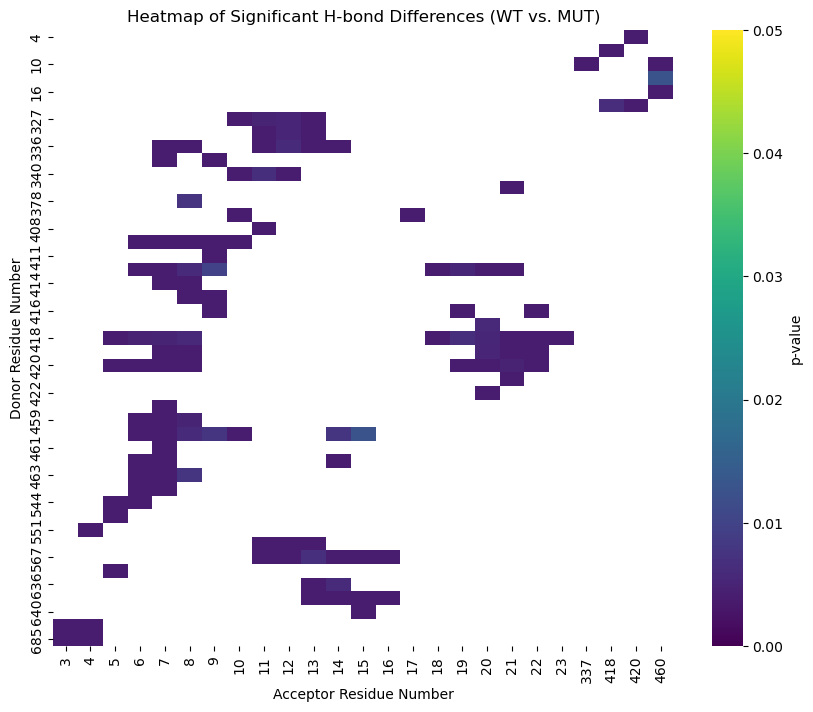

In [90]:
# Reset index to make donor_res_num_adjusted and acceptor_res_num_adjusted columns
significant_diff_reset = significant_diff.reset_index()

# Create a pivot table for the heatmap
heatmap_data = significant_diff_reset.pivot_table(
    index='donor_res_num_adjusted', 
    columns='acceptor_res_num_adjusted', 
    values='p_value', 
    #fill_value=1  # Use 1 (non-significant) for missing values
)

# Plot the heatmap
plt.figure(figsize=(10, 8))  # Adjust size as needed
sns.heatmap(
    heatmap_data, 
    cmap='viridis', 
    vmin=0, vmax=0.05,  # Focus on significant p-values 
    #annot=True, 
    fmt='.3f',  # Format annotations to 3 decimal places
    cbar_kws={'label': 'p-value'}  # Label the color bar
)

# Add labels and title
plt.xlabel('Acceptor Residue Number')
plt.ylabel('Donor Residue Number')
plt.title('Heatmap of Significant H-bond Differences (WT vs. MUT)')
plt.show()

In [93]:
significant_diff_reset[significant_diff_reset['donor_res_num_adjusted'] ==466].sort_values('p_value', ascending=False).head()

,donor,acceptor,donor_res_num_adjusted,acceptor_res_num_adjusted,WT_mean,WT_std,MUT,p_value
172,5476,19040,466,6,0.0,0.0,4,0.00404
173,5476,19042,466,7,0.0,0.0,295,0.00404
174,5476,19043,466,7,0.0,0.0,494,0.00404
175,5479,19042,466,7,0.0,0.0,351,0.00404
176,5479,19043,466,7,0.0,0.0,634,0.00404


In [94]:
combined_df = pd.concat([wt_agg, mut_agg], ignore_index=True)

In [95]:
# Filter for residue 466
residue_466_df = combined_df[
    (combined_df['donor_res_num_adjusted'] == 466) | 
    (combined_df['acceptor_res_num_adjusted'] == 466)
]

In [96]:
# Separate WT and MUT data for residue v
wt_466 = residue_466_df[residue_466_df['group'] == 'WT']
mut_466 = residue_466_df[residue_466_df['group'] == 'MUT']

# Perform statistical tests
t_stat, t_pval = ttest_ind(wt_466['count'], mut_466['count'], equal_var=False)
u_stat, u_pval = mannwhitneyu(wt_466['count'], mut_466['count'])

print(f"T-test p-value: {t_pval}")
print(f"Mann-Whitney U test p-value: {u_pval}")

T-test p-value: nan
Mann-Whitney U test p-value: nan


/home/irati/miniconda3/envs/thesis_md/lib/python3.12/site-packages/scipy/_lib/deprecation.py:234: SmallSampleWarning: One or more sample arguments is too small; all returned values will be NaN. See documentation for sample size requirements.
  return f(*args, **kwargs)
/tmp/ipykernel_126366/2391925621.py:7: SmallSampleWarning: One or more sample arguments is too small; all returned values will be NaN. See documentation for sample size requirements.
  u_stat, u_pval = mannwhitneyu(wt_466['count'], mut_466['count'])


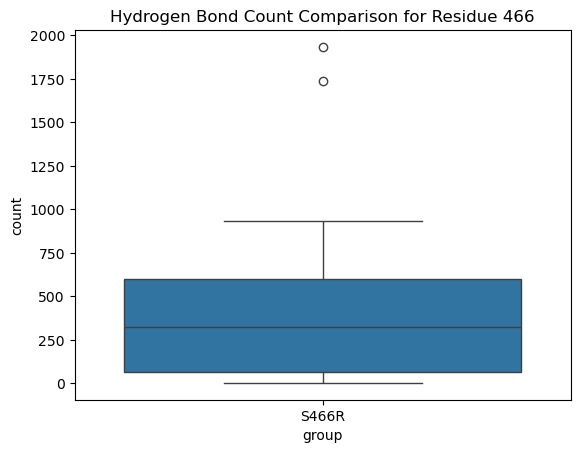

In [99]:
sns.boxplot(data=residue_466_df, x='group', y='count')
plt.title('Hydrogen Bond Count Comparison for Residue 466')
plt.show()